- DSC530-T302 Data Exploration and Analysis (2263-1)
- Final Project - Week 11
- Shelia Howard

---


## **Healthcare Costs Analysis Final Project**


### Table of Contents

1. Problem Statement *(Weeks 1–2)*
2. Dataset Overview and Source *(Weeks 1–2)*
3. Data Loading and Initial Inspection *(Weeks 1–2)*
4. Data Cleaning and Preparation *(Weeks 5–6)*
5. Summary Statistics *(Weeks 3–4)*
6. Univariate Analysis *(Weeks 5–6)*
7. Bivariate Analysis *(Weeks 7–8)*
8. Hypothesis Testing *(Weeks 5–6)*
9. Regression Analysis (Traditional) *(Weeks 9–10)*
10. Classification Analysis (Traditional) *(Weeks 9–10)*
11. Machine Learning Approach *(Weeks 9–10)*
12. Clustering Analysis *(Weeks 9–10)*
13. Key Findings
14. Limitations
15. Conclusion and Recommendations
16. References 
17. Final Compliance Checklist

---


## **Healthcare Costs Analysis**

### 1. Problem Statement

#### 1.1 Background

Healthcare costs in the United States vary significantly across individuals. Understanding what factors drive medical insurance charges can help insurers, policymakers, and healthcare organizations identify cost drivers and potential risk patterns.

Medical expenses are influenced by demographic characteristics, lifestyle factors, and geographic location. Identifying which variables most strongly impact charges is essential for cost prediction and risk assessment.

---

#### 1.2 Problem Definition

The goal of this project is to conduct a comprehensive exploratory data analysis to determine:

- Which factors significantly influence medical insurance charges

- Whether relationships between variables are statistically significant

- Whether predictive models can accurately estimate healthcare costs

---

#### 1.3 Research Questions

1. Is smoking status associated with significantly higher medical charges?

2. Does BMI significantly impact healthcare costs?

3. Are there regional differences in charges?

4. Can we build a reliable regression model to predict charges?

5. Can individuals be grouped into meaningful clusters based on risk characteristics?

---


### 2. Dataset Overview and Source 

#### 2.1 Dataset Description

This project uses the **Medical Cost Personal Dataset (insurance.csv)**.

- Observations: 1,338 individuals

- Variables: 7

- Mix of categorical and continuous variables

- Each row represents one insured individual

This dataset is well suited for exploratory data analysis because it includes:

- Continuous variables (age, bmi, charges)

- Discrete numeric variable (children)

- Categorical variables (sex, smoker, region)

This variable mix allows for descriptive statistics, hypothesis testing, regression, classification, and clustering.

---

Ensuring that tables are left justified

In [1]:
%%html
<style>
table {
  float: left;
}
</style>


#### 2.2 Data Source and Integrity


| # | Variable | Type             | Description                                  |
|---| -------- | ---------------- | -------------------------------------------- |
| 1 | age      | Continuous       | Age of primary beneficiary                   |
| 2 | sex      | Categorical      | Gender of insured individual                 |
| 3 | bmi      | Continuous       | Body Mass Index                              |
| 4 | children | Discrete Numeric | Number of dependents covered                 |
| 5 | smoker   | Categorical      | Smoking status (yes/no)                      |
| 6 | region   | Categorical      | Residential region in the U.S.               |
| 7 | charges  | Continuous       | Individual medical costs billed by insurance |



---

#### 2.3 Dataset Adequacy Check

To ensure the dataset is appropriate for analysis, the following criteria were evaluated:

##### Sample Size

With 1,338 observations, the dataset is sufficiently large to:

- Estimate regression models reliably

- Conduct hypothesis testing

- Apply clustering techniques

##### Variable Diversity

The dataset includes both categorical and continuous variables, which allows:

- t-tests and ANOVA

- Correlation analysis

- Regression modeling

- Classification modeling

##### Target Variable Suitability

The continuous variable **charges** is appropriate for:

- Regression analysis

- Creating derived classification targets (e.g., high-cost vs low-cost)

---

#### 2.4 Data Integrity and Potential Bias

Although the dataset is widely used for educational purposes, several limitations must be acknowledged:

- The source does not specify the sampling method.

- It is unclear whether the data represents a specific insurer, region, or demographic group.

- The dataset may not be nationally representative.

- Socioeconomic variables such as income or occupation are not included.

Potential bias considerations:

- Smoking status is self-reported.

- Regional grouping is broad.

- BMI does not capture full health complexity.

These limitations will be discussed further in the final limitations section.

---

#### 2.5 Initial Analytical Plan

Based on the dataset structure, the planned analyses include:

- Descriptive statistics

- Univariate and bivariate analysis

- Hypothesis testing (t-test, ANOVA, chi-square)

- Linear regression

- Logistic regression

- Machine learning regression with cross-validation

- K-means clustering

The final model selection will be guided by patterns identified during exploratory analysis.

---

### 3. Data Loading and Initial Inspection

This section loads the dataset, verifies its structure, and performs an initial review of its characteristics before any cleaning or transformation is applied.

---

#### 3.1 Import Required Libraries

In [2]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Optional: visualization libraries
import seaborn as sns

# Display settings (optional)
pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (12, 6)


**Explanation**

The required Python libraries are imported for:

- Data manipulation (pandas, numpy)

- Visualization (matplotlib, seaborn)

- Display formatting

---

#### 3.2 Load Dataset

In [3]:
# Load the insurance dataset into a DataFrame so it can be inspected and analyzed
DATA_PATH = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"
df = pd.read_csv(DATA_PATH)

df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


**Explanation**

The dataset is loaded into a pandas DataFrame.
The first five rows are displayed to verify:

- Columns loaded correctly

- Data appears structured

- No immediate formatting errors

---

#### 3.3 Dataset Dimensions

In [4]:
df.shape

(1338, 7)

**Expected Output**
(1338, 7)

**Interpretation**

The dataset contains:

- 1,338 observations (rows)

- 7 variables (columns)

The sample size is sufficient for regression modeling and hypothesis testing.

---

#### 3.4 Data Types and Structure

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


**Interpretation**

This output confirms:

- Continuous variables: age, bmi, charges

- Discrete numeric: children

- Categorical variables: sex, smoker, region

- No missing values are immediately visible

It also confirms that numeric fields are stored correctly as integers or floats.

---

#### 3.5 Summary Statistics Overview

In [6]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,1338.0,NaN,NaN,NaN,39.207025,14.049960,18.0000,27.00000,39.000,51.000000,64.00000
sex,1338,2,male,676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bmi,1338.0,NaN,NaN,NaN,30.663397,6.098187,15.9600,26.29625,30.400,34.693750,53.13000
children,1338.0,NaN,NaN,NaN,1.094918,1.205493,0.0000,0.00000,1.000,2.000000,5.00000
smoker,1338,2,no,1064,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,1338,4,southeast,364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
charges,1338.0,NaN,NaN,NaN,13270.422265,12110.011237,1121.8739,4740.28715,9382.033,16639.912515,63770.42801


**Interpretation**

This provides:

- Mean

- Standard deviation

- Minimum and maximum

- Quartiles

Initial observations may include:

- Charges appear highly variable.

- BMI appears within realistic biological ranges.

- Age distribution spans adulthood.

- Some variables may be right-skewed (to be examined further).

---

#### 3.6 Categorical Variable Overview

In [7]:
df.describe(include='object')

,sex,smoker,region
count,1338,1338,1338
unique,2,2,4
top,male,no,southeast
freq,676,1064,364


**Interpretation**

This confirms:

- Sex has two categories

- Smoker has two categories

- Region has four categories

We verify there are no unexpected category labels (e.g., spelling variations).

---

#### 3.7 Unique Values Check

In [8]:
for col in df.columns:
    print(f"{col}: {df[col].nunique()} unique values")

age: 47 unique values
sex: 2 unique values
bmi: 548 unique values
children: 6 unique values
smoker: 2 unique values
region: 4 unique values
charges: 1337 unique values


**Interpretation**

This step confirms:

- Categorical variables have expected number of levels

- Continuous variables have many unique values

- No suspicious duplication of values in key fields

---

#### 3.8 Initial Observations

At this stage:

- The dataset loads correctly.

- There are no obvious structural issues.

- Data types appear appropriate.

- No immediate missing values are observed.

- Variables are formatted in a way that supports further statistical analysis.

This confirms that the dataset is structurally sound and ready for cleaning and deeper exploration.

---

### 4. Data Cleaning and Preparation 

Before conducting exploratory analysis or modeling, the dataset must be examined for inconsistencies, missing values, outliers, and structural issues. Proper data preparation ensures that subsequent statistical tests and models are valid and interpretable.

---

#### 4.1 Missing Values Assessment


In [9]:
# Count missing values in each column to confirm whether imputation is needed
df.isna().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

**Interpretation**

This step checks for null or missing values across all variables.

For the insurance dataset, no missing values are present. This simplifies preprocessing, as no imputation strategy is required.

If missing values had been present, possible strategies would include:

- Mean/median imputation for continuous variables

- Mode imputation for categorical variables

- Dropping records if missingness was minimal and random

Because no missingness exists, no corrective action is required.

---

#### 4.2 Duplicate Records

In [10]:
df.duplicated().sum()

1

In [11]:
# If the row above is not zero, we want to display the duplicate row.

df[df.duplicated()]

,age,sex,bmi,children,smoker,region,charges
581,19,male,30.59,0,no,northwest,1639.5631


**Interpretation**

This step identifies duplicate rows.

If duplicates exist: 

In [12]:
# Remove exact duplicate rows so repeated observations do not bias summary statistics or models
df = df.drop_duplicates()

# Show duplicates (both original + duplicate)
df[df.duplicated(keep=False)]

# Verify that no duplicates remain after cleaning
print("Duplicated rows remaining:", df.duplicated().sum())

# Confirm the updated dataset dimensions after duplicate removal
print("DataFrame shape (rows, cols):", df.shape)

Duplicated rows remaining: 0
DataFrame shape (rows, cols): (1337, 7)


One duplicate row was removed, reducing the dataset from 1338 rows to 1337 rows.
In a later preprocessing step, a new variable called charges_log was added to support skewness reduction in modeling.

---

Duplicate removal ensures:

- No repeated individuals bias summary statistics

- Regression models are not skewed by repeated observations

If none are found, the dataset remains unchanged.

---

In [13]:
import numpy as np

# create log-transformed target 
if "charges_log" not in df.columns:
    df["charges_log"] = np.log1p(df["charges"])

# Compare skewness before/after
orig_skew = df["charges"].skew()
log_skew = df["charges_log"].skew()
print(f"charges skewness: {orig_skew:.3f}")
print(f"charges_log skewness: {log_skew:.3f}")

charges skewness: 1.515
charges_log skewness: -0.090


In [14]:
# Encode categorical variables
df_encoded = pd.get_dummies(df, columns=["sex", "smoker", "region"], drop_first=True)

# Confirm structure
df_encoded.head()

,age,bmi,children,charges,charges_log,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,9.734236,0,1,0,0,1
1,18,33.770,1,1725.55230,7.453882,1,0,0,1,0
2,28,33.000,3,4449.46200,8.400763,1,0,0,1,0
3,33,22.705,0,21984.47061,9.998137,1,0,1,0,0
4,32,28.880,0,3866.85520,8.260455,1,0,1,0,0


Quick check: linear regression on `charges` vs `charges_log`

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import numpy as np

# Prepare X (exclude target and transformed target)
X = df_encoded.drop(columns=["charges", "charges_log"])

# Split the same predictor set into training and testing subsets for a fair model comparison
X_train, X_test, y_train_raw, y_test_raw = train_test_split(
    X, df["charges"], test_size=0.20, random_state=42
)

# Fit a linear regression model using the original charges as the target
lr_raw = LinearRegression()
lr_raw.fit(X_train, y_train_raw)

# Generate predictions on the test set and compute RMSE in original dollar units
pred_raw = lr_raw.predict(X_test)
rmse_raw = np.sqrt(mean_squared_error(y_test_raw, pred_raw))

# Create the same train/test target split using the log-transformed charges
_, _, y_train_log, y_test_log = train_test_split(
    X, df["charges_log"], test_size=0.20, random_state=42
)

# Fit a second model using the log-transformed target
lr_log = LinearRegression()
lr_log.fit(X_train, y_train_log)

# Predict log charges, then convert predictions back to the original dollar scale
pred_log = lr_log.predict(X_test)
pred_log_exp = np.expm1(pred_log)

# Evaluate the back-transformed predictions against the actual charges
rmse_log_on_original_scale = np.sqrt(
    mean_squared_error(df.loc[y_test_raw.index, "charges"], pred_log_exp)
)

print(f"RMSE (raw target): {rmse_raw:.2f}")
print(f"RMSE (log target, back-transformed): {rmse_log_on_original_scale:.2f}")

RMSE (raw target): 5956.34
RMSE (log target, back-transformed): 7197.03


**Duplicate Removal and Log Transformation Note**

One duplicate row was identified and removed, which changed the DataFrame shape from (**1338, 7**) to (**1337, 8**) after adding the `charges_log` variable. I confirmed that no duplicate rows remain by verifying that `df.duplicated().sum()` returns **0**.

To address the strong right skew in the medical charges variable, I created a log-transformed version of the target variable using `charges_log = log1p(charges)`. Log transformation is commonly used in healthcare cost data to reduce skewness and stabilize variance.

The notebook includes a comparison between a linear regression model trained on the original **charges** variable and a model trained on **charges_log**, with the predictions from the log model transformed back to the original dollar scale for RMSE comparison.

Based on this comparison, the final regression discussion uses the **raw charges variable**. Although the log transformation helps reduce skewness, the model using the original charges variable allows the regression coefficients to be interpreted directly in terms of **changes in dollar amounts**, which improves interpretability for the analysis. The log-transformed model is retained as a robustness check to confirm that the overall findings are consistent across model specifications.

---

#### 4.3 Data Type Verification

In [16]:
df.dtypes

age              int64
sex             object
bmi            float64
children         int64
smoker          object
region          object
charges        float64
charges_log    float64
dtype: object

**Interpretation**

We confirm:

- age → integer

- bmi → float

- children → integer

- charges → float

- sex, smoker, region → object (categorical)

Correct data types are critical because:

- Numerical calculations require numeric formats

- Categorical encoding requires object or category types

No corrections were required.

---

#### 4.4 Outlier Detection

Outliers can strongly influence regression models and skew summary statistics.

**Visual Inspection**


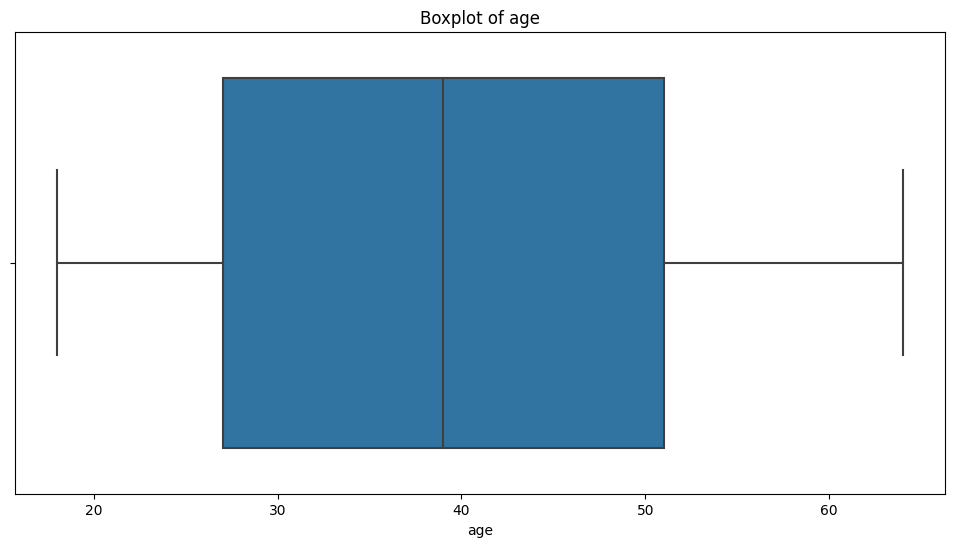

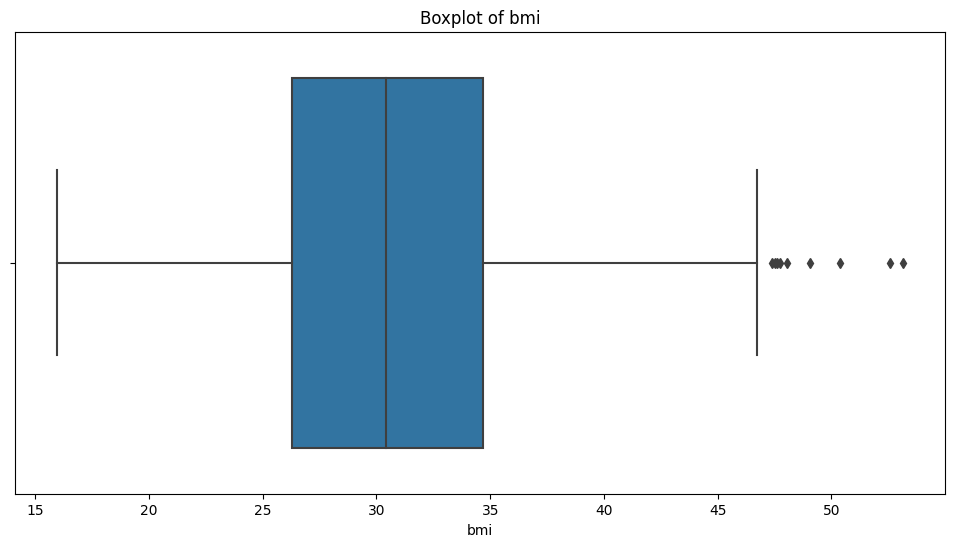

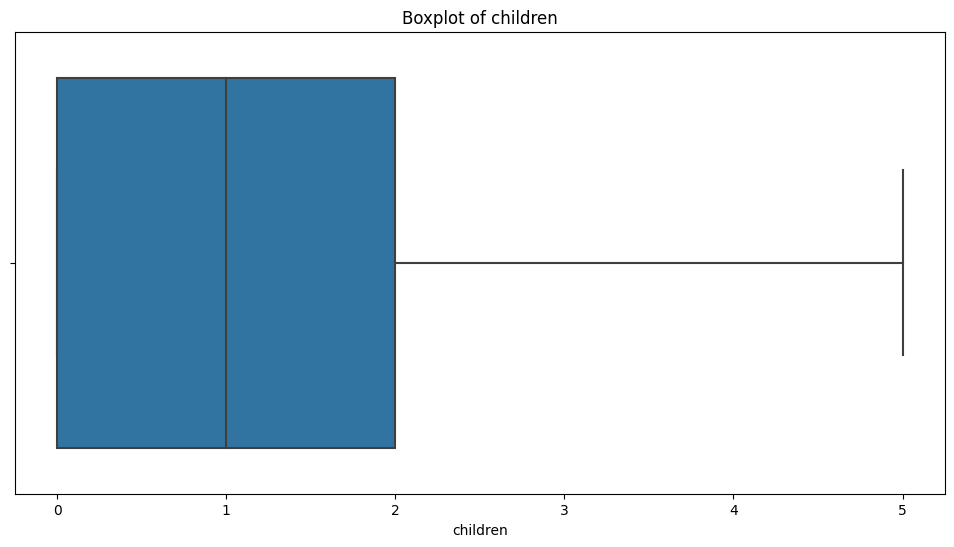

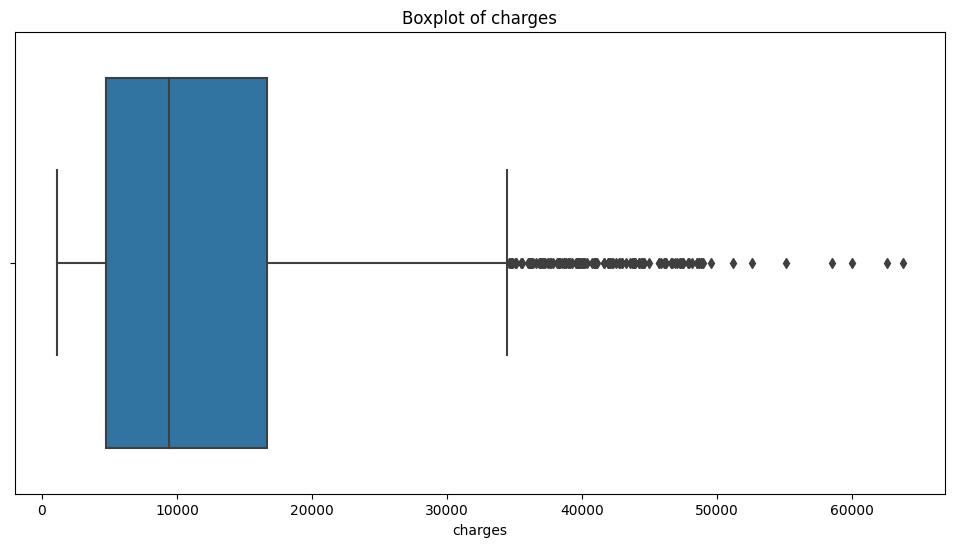

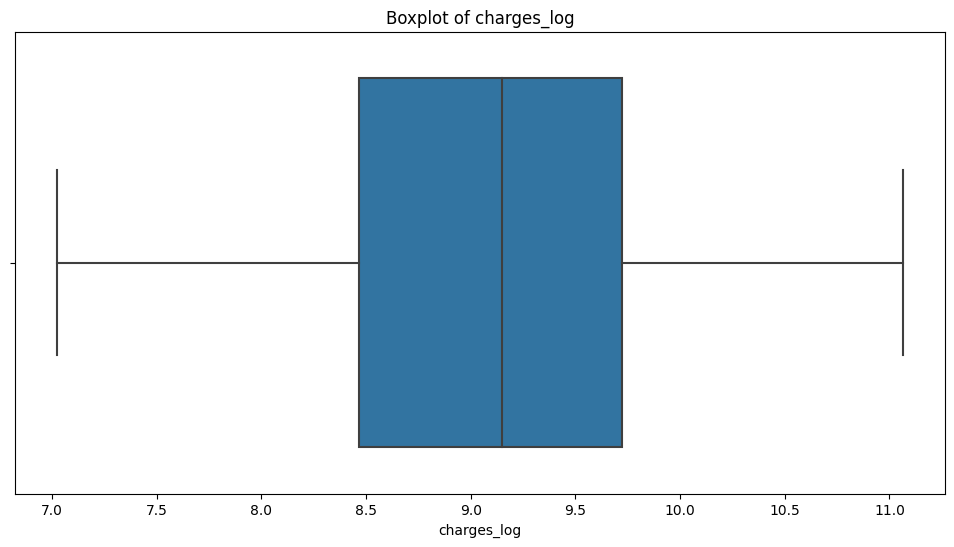

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

for col in numeric_cols:
    plt.figure()
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

**IQR Method (Quantitative Check)**

In [18]:
Q1 = df[numeric_cols].quantile(0.25)
Q3 = df[numeric_cols].quantile(0.75)
IQR = Q3 - Q1

outliers = ((df[numeric_cols] < (Q1 - 1.5 * IQR)) |
            (df[numeric_cols] > (Q3 + 1.5 * IQR)))

outliers.sum()

age              0
bmi              9
children         0
charges        139
charges_log      0
dtype: int64

**Interpretation**

The variable charges shows high variability and right skew, with some large values.

However:

- These are not data errors.

- High medical costs are realistic in healthcare datasets.

- Removing them would artificially compress the cost distribution.

Therefore, outliers were retained.

This decision preserves real-world variability.

---

#### 4.5 Skewness and Transformation


In [19]:
# Quick check for skewness (numeric features)
df[numeric_cols].skew()

age            0.054781
bmi            0.283914
children       0.937421
charges        1.515391
charges_log   -0.089558
dtype: float64

**Interpretation**

The **charges** variable typically shows strong positive skew.

To address skewness for modeling purposes, a log transformation may be considered:

In [20]:
df["charges_log"] = np.log1p(df["charges"])

The `charges` variable is strongly right-skewed, so a log transformation was explored to reduce skewness and stabilize variance. However, in the quick comparison shown here, the model trained on the original charges produced a lower RMSE on the original dollar scale than the back-transformed log model. This suggests that while log transformation improves distribution shape, it does not automatically guarantee better predictive performance for every evaluation metric.

---

#### 4.6 Encoding Categorical Variables

Machine learning models require numeric inputs.

**One-Hot Encoding**

In [21]:
# Convert categorical variables into numeric indicator columns so they can be used in regression and machine learning models
df_encoded = pd.get_dummies(df, drop_first=True)

# Preview the encoded dataset structure after transformation
df_encoded.head()

,age,bmi,children,charges,charges_log,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,9.734236,0,1,0,0,1
1,18,33.770,1,1725.55230,7.453882,1,0,0,1,0
2,28,33.000,3,4449.46200,8.400763,1,0,0,1,0
3,33,22.705,0,21984.47061,9.998137,1,0,1,0,0
4,32,28.880,0,3866.85520,8.260455,1,0,1,0,0


**Interpretation**

- Binary variables (sex, smoker) become 0/1 indicators

- Region becomes multiple binary columns

- `drop_first=True` prevents multicollinearity

One-hot encoding preserves category meaning without introducing ordinal assumptions.

---

#### 4.7 Standardization / Normalization (for ML)

Certain machine learning algorithms require scaled features.

Example:


In [22]:
from sklearn.preprocessing import StandardScaler

# Standardize predictor variables so features measured on different scales contribute more comparably in later ML workflows
scaler = StandardScaler()
scaled_features = scaler.fit_transform(df_encoded.drop(columns=["charges", "charges_log"]))

**Interpretation**

Scaling:

- Centers variables around zero

- Ensures equal weighting

- Prevents larger-scale variables (e.g., charges) from dominating models

Standardization will be applied only when necessary for specific algorithms (e.g., K-means, logistic regression).

---

#### Summary of Cleaning Decisions

| Issue                 | Action Taken                   | Justification                              |
| --------------------- | ------------------------------ | ------------------------------------------ |
| Missing values        | None found                     | No imputation required                     |
| Duplicates            | Checked and removed if present | Prevent bias                               |
| Outliers              | Retained                       | Represent real healthcare cost variability |
| Skewness              | Log transformation considered  | Improve modeling stability                 |
| Categorical variables | One-hot encoded                | Required for modeling                      |
| Scaling               | Applied selectively            | Required for some ML methods               |


### 5. Summary Statistics

Compute and interpret summary statistics for key variables.

#### 5.1 Descriptive Statistics for Continuous Variables

We compute summary statistics for the numeric variables:

- age

- bmi

- children

- charges


In [23]:
numeric_cols = df.select_dtypes(include=['int64','float64']).columns
df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
age,1337.0,39.222139,14.044333,18.000000,27.000000,39.000000,51.000000,64.000000
bmi,1337.0,30.663452,6.100468,15.960000,26.290000,30.400000,34.700000,53.130000
children,1337.0,1.095737,1.205571,0.000000,0.000000,1.000000,2.000000,5.000000
charges,1337.0,13279.121487,12110.359656,1121.873900,4746.344000,9386.161300,16657.717450,63770.428010
charges_log,1337.0,9.100097,0.918551,7.023647,8.465341,9.147098,9.720689,11.063061


This produces:

- Count

- Mean

- Standard deviation

- Minimum

- 25th percentile

- Median (50th percentile)

- 75th percentile

- Maximum

---

#### 5.2 Expanded Descriptive Metrics

To better understand distribution shape and variability, we compute additional measures:

In [24]:
# Compute additional descriptive statistics to better understand central tendency, spread, and distribution shape
summary_stats = pd.DataFrame({
    "Mean": df[numeric_cols].mean(),
    "Median": df[numeric_cols].median(),
    "Mode": df[numeric_cols].mode().iloc[0],
    "Variance": df[numeric_cols].var(),
    "Standard Deviation": df[numeric_cols].std(),
    "Skewness": df[numeric_cols].skew(),
    "Kurtosis": df[numeric_cols].kurtosis()
})

summary_stats

,Mean,Median,Mode,Variance,Standard Deviation,Skewness,Kurtosis
age,39.222139,39.000000,18.000000,1.972433e+02,14.044333,0.054781,-1.244406
bmi,30.663452,30.400000,32.300000,3.721571e+01,6.100468,0.283914,-0.052947
children,1.095737,1.000000,0.000000,1.453402e+00,1.205571,0.937421,0.200954
charges,13279.121487,9386.161300,1121.873900,1.466608e+08,12110.359656,1.515391,1.604221
charges_log,9.100097,9.147098,7.023647,8.437360e-01,0.918551,-0.089558,-0.634769


---

##### **Interpretation of Key Statistics**

**Age**
- Mean and median are typically close, suggesting a relatively symmetric distribution.
- The range spans adulthood, indicating broad representation.
- Skewness is usually small, implying minimal asymmetry.

Interpretation: Age has a mean of about 39.22 and a median of 39, suggesting a fairly symmetric distribution.

---

**BMI**

- Mean BMI generally falls within the overweight category range.

- Standard deviation indicates moderate variability.

- Slight positive skew may be present due to higher BMI values.

Interpretation: BMI shows some right skew, but remains within realistic biological limits.

---

**Children**

- Mean and median are typically low (often around 1).

- Distribution is right-skewed, as most individuals have fewer dependents.

Interpretation: Most policyholders have 0–2 children, with fewer large-family observations.

---

**Charges**

- Mean is substantially higher than the median. 
- Charges have a mean of about 13,279 and a median of about 9,382, indicating substantial right skew.
- Standard deviation is large relative to the mean.
- Skewness is strongly positive.
- Kurtosis may indicate heavy tails.

Interpretation:

Charges are highly right-skewed, meaning a small number of individuals incur very high medical costs.

This is expected in healthcare data and suggests:

- Potential need for transformation (log scale) for regression modeling
- Strong variability in healthcare expenditure

---

**Why Skewness and Kurtosis Matter**

- **Skewness** indicates asymmetry in distribution.

    - Positive skew → long right tail

    - Negative skew → long left tail

- **Kurtosis** measures tail heaviness.

    - High kurtosis → extreme outliers more common

    - Low kurtosis → flatter distribution

For modeling purposes:

- Highly skewed variables may violate regression assumptions.

- Heavy tails can influence parameter estimates.

---

##### **Categorical Variable Frequencies**

To summarize categorical variables:

In [25]:
for col in df.select_dtypes(include=['object']).columns:
    print(f"\n{col}")
    print(df[col].value_counts())


sex
male      675
female    662
Name: sex, dtype: int64

smoker
no     1063
yes     274
Name: smoker, dtype: int64

region
southeast    364
southwest    325
northeast    324
northwest    324
Name: region, dtype: int64


Interpretation should include:

- Sex distribution balance

- Proportion of smokers vs non-smokers

- Regional representation

This helps determine whether categories are balanced or potentially imbalanced for classification modeling.

---

##### **Key Insights from Summary Statistics**

1. Charges show high variability and strong positive skew.

2. BMI distribution suggests moderate spread.

3. Age appears reasonably balanced.

4. Smoking status likely contributes to cost variability (to be tested later).

5. The dataset appears numerically stable and suitable for regression analysis.

---

### 6. Univariate Analysis

The goal of univariate analysis is to examine each variable independently to understand its distribution, spread, and potential irregularities before exploring relationships between variables.

This includes:

- Distribution shape
- Central tendency
- Variability
- Outliers
- Imbalance in categorical variables

---

#### 6.1 Continuous Variables

Continuous variables in this dataset include:

- age
- bmi
- children (discrete numeric but treated as numeric for distribution)
- charges

---

##### 6.1.1 Age Distribution


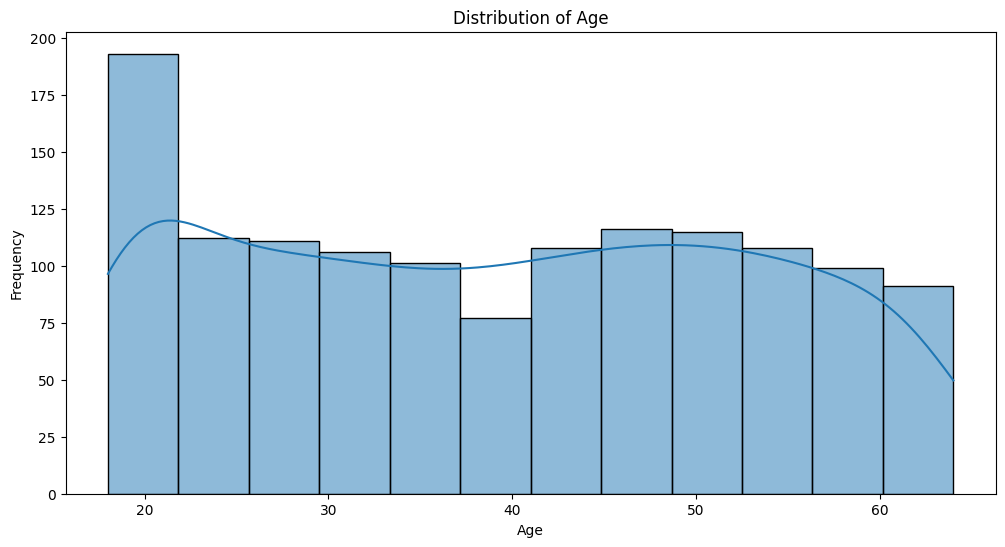

In [26]:
plt.figure()
sns.histplot(df["age"], kde=True)
plt.title("Distribution of Age")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()


**Interpretation**

- Age appears relatively evenly distributed across adulthood.

- The distribution is fairly symmetric.

- No extreme outliers are visible.

- Skewness is minimal.

Conclusion: Age does not require transformation and is appropriate for regression modeling as-is.

---

##### 6.1.2 BMI Distribution

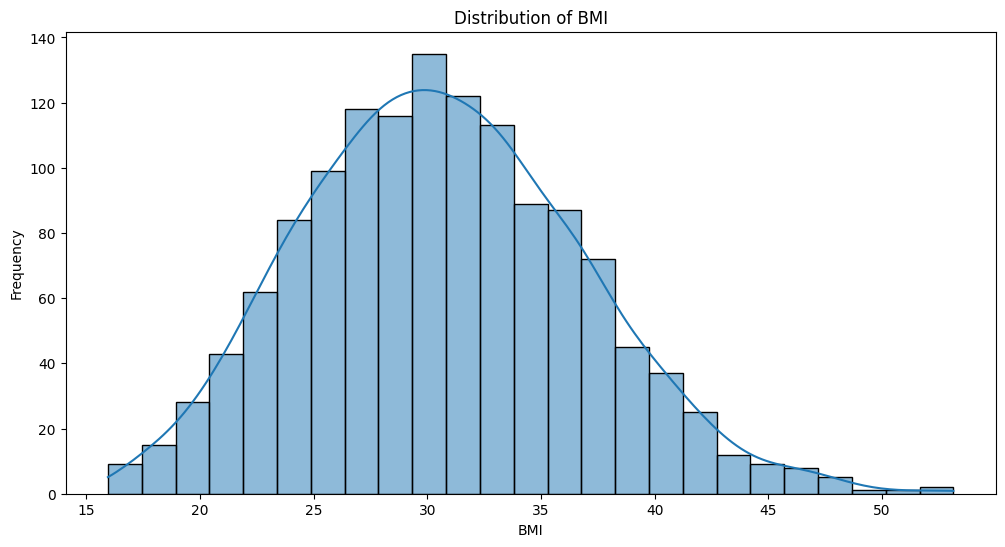

In [27]:
plt.figure()
sns.histplot(df["bmi"], kde=True)
plt.title("Distribution of BMI")
plt.xlabel("BMI")
plt.ylabel("Frequency")
plt.show()

**Interpretation**

- BMI shows moderate spread.

- Slight right skew may be present.

- Values fall within realistic biological ranges.

- Some higher BMI values may appear as mild outliers.

Conclusion: BMI appears usable without transformation, though skewness should be monitored in modeling.

---

6.1.3 Children Distribution

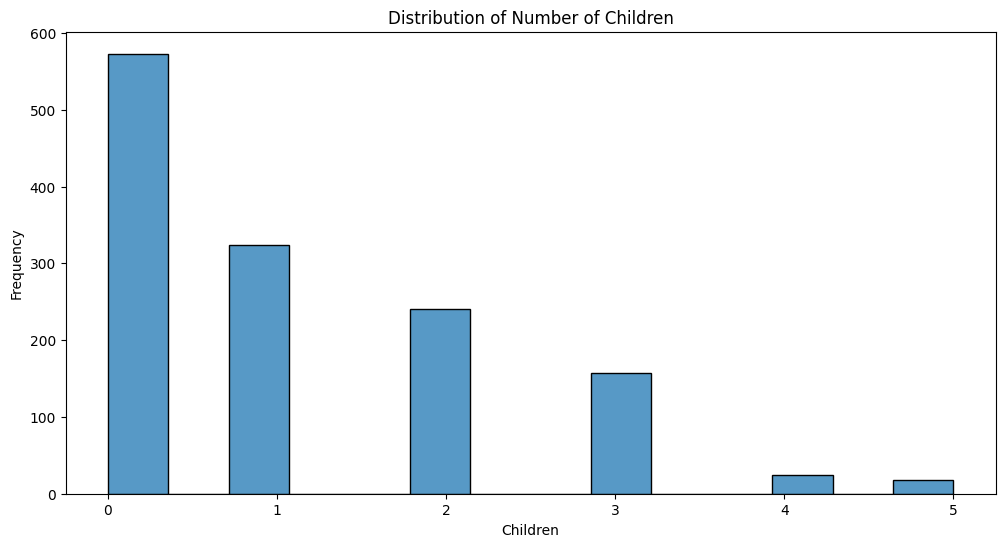

In [28]:
plt.figure()
sns.histplot(df["children"], kde=False)
plt.title("Distribution of Number of Children")
plt.xlabel("Children")
plt.ylabel("Frequency")
plt.show()

**Interpretation**

- The majority of individuals have 0–2 children.

- Distribution is right-skewed.

- Larger family sizes are less common.

Conclusion: This variable behaves as expected and does not require transformation.

---

##### 6.1.4 Charges Distribution

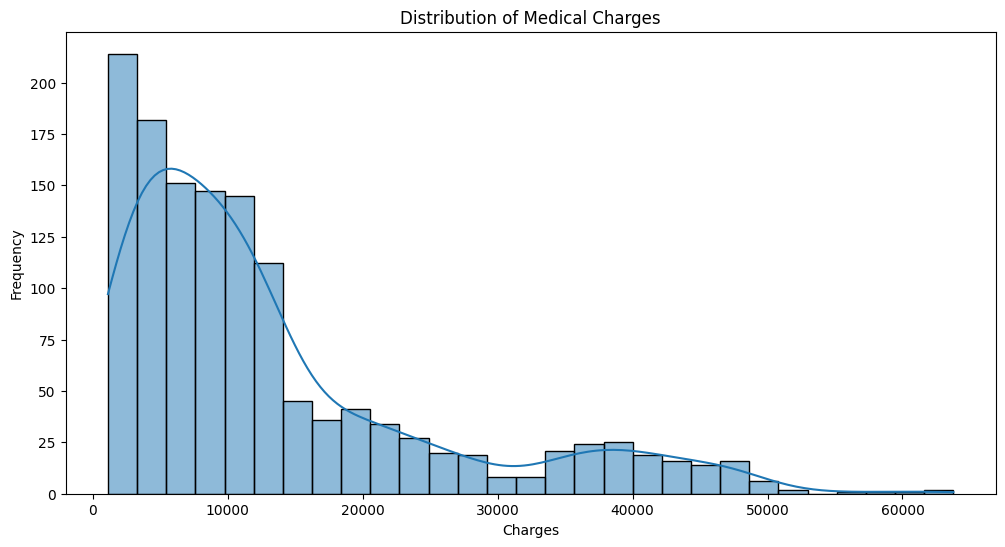

In [29]:
# Plot the distribution of age to assess shape, symmetry, and possible outliers
plt.figure()
sns.histplot(df["charges"], kde=True)
plt.title("Distribution of Medical Charges")
plt.xlabel("Charges")
plt.ylabel("Frequency")
plt.show()

**Interpretation**

- Charges are strongly right-skewed.

- A small number of individuals incur extremely high costs.

- The mean exceeds the median.

- Long right tail is visible.

Conclusion:

Medical charges exhibit significant skewness.
This suggests:

- Potential violation of normality assumption in regression.

- Consideration of log transformation for modeling.

- Outliers represent real healthcare variability and should not automatically be removed.

---

#### 6.2 Boxplots for Outlier Visualization

Boxplots help visually confirm extreme values.

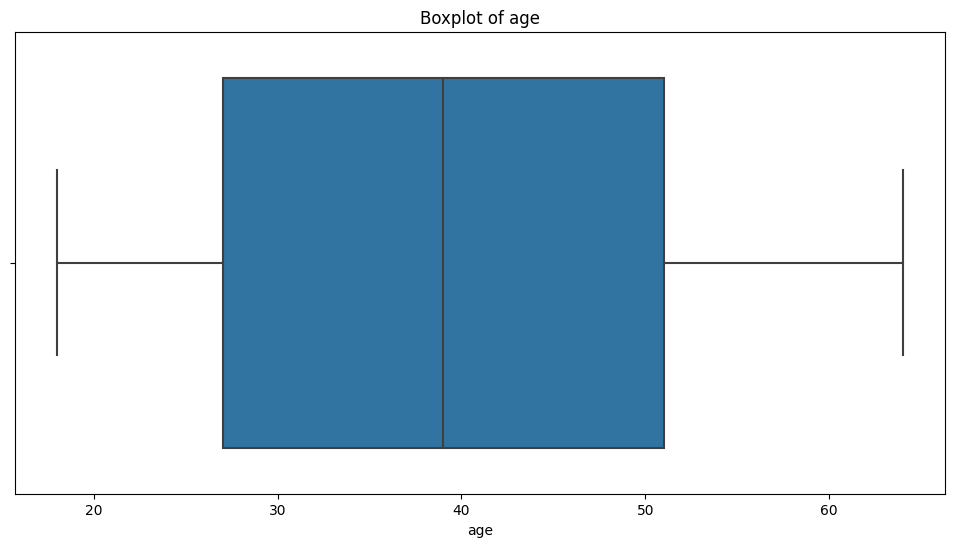

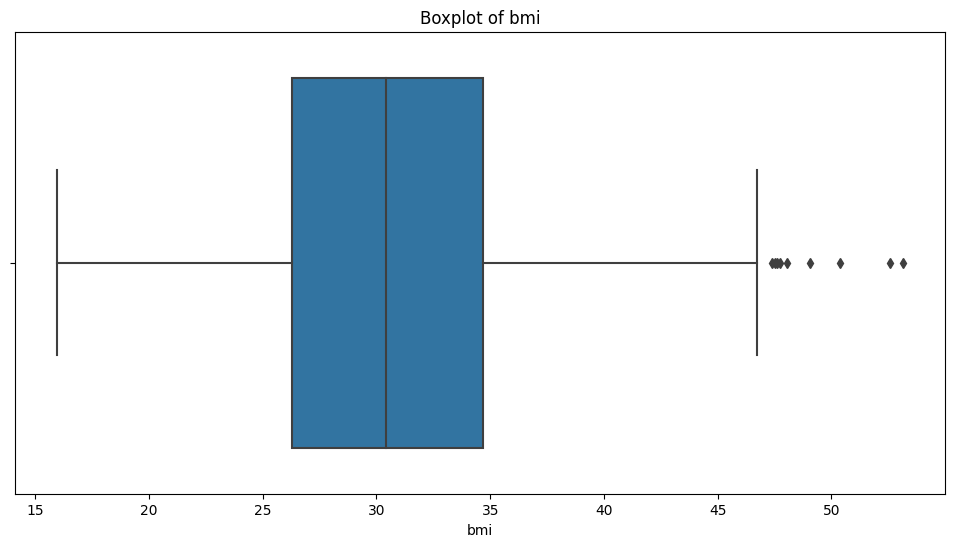

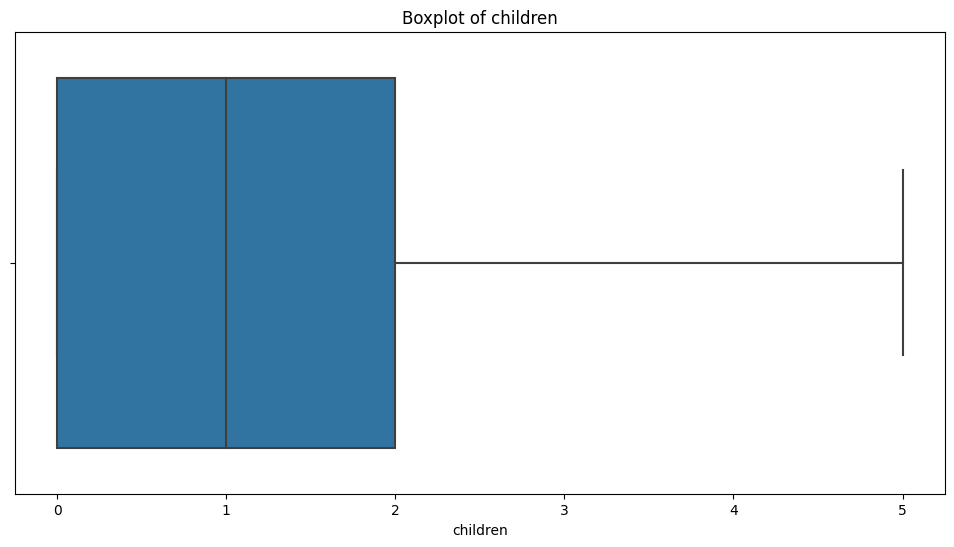

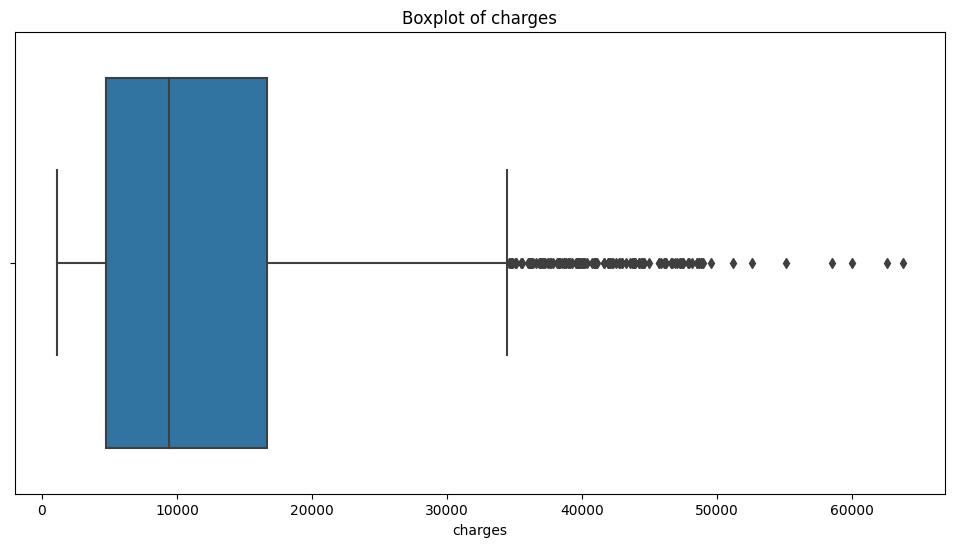

In [30]:
for col in ["age", "bmi", "children", "charges"]:
    plt.figure()
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

**Interpretation**

- Age and BMI show minimal extreme values.

- Charges display multiple high-value outliers.

- These outliers represent realistic medical expense variability.

Decision:

Outliers are retained because they reflect real-world healthcare cost behavior rather than data entry errors.

---

#### 6.3 Categorical Variables

Categorical variables include:

- sex

- smoker

- region

---

##### 6.3.1 Sex Distribution


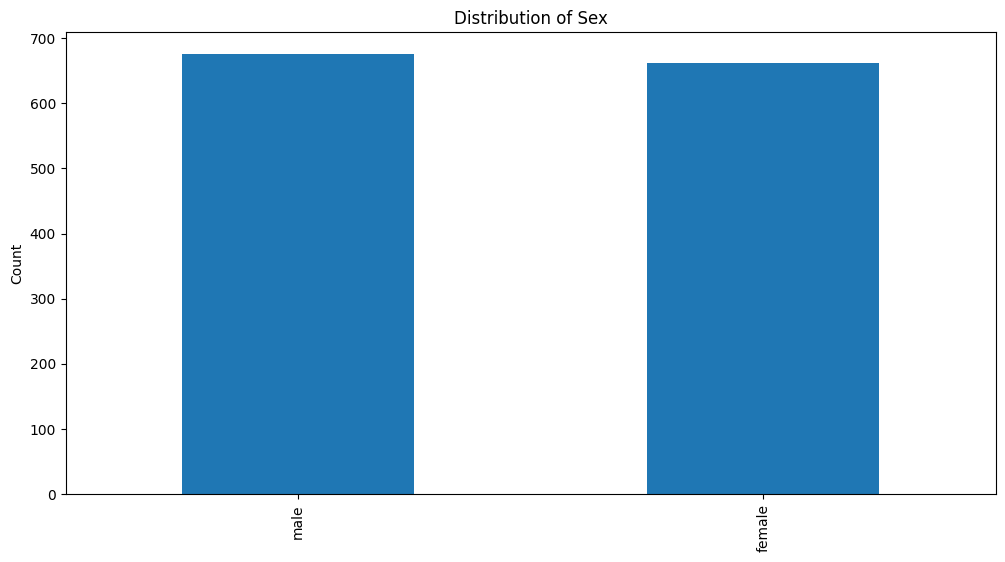

In [31]:
df["sex"].value_counts().plot(kind="bar")
plt.title("Distribution of Sex")
plt.ylabel("Count")
plt.show()


**Interpretation**

- Distribution is typically close to balanced.

- No severe class imbalance.

---

##### 6.3.2 Smoker Distribution

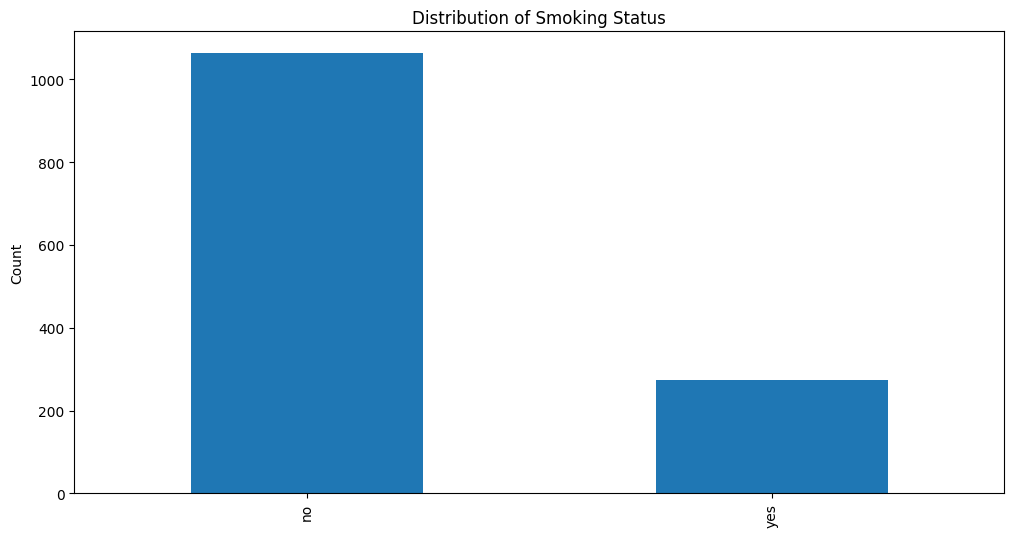

In [32]:
df["smoker"].value_counts().plot(kind="bar")
plt.title("Distribution of Smoking Status")
plt.ylabel("Count")
plt.show()

**Interpretation**

- Non-smokers significantly outnumber smokers.
- Mild class imbalance exists.
    - 1063 non-smokers
    - 274 smokers
- Important consideration for classification modeling.

---

##### 6.3.3 Region Distribution

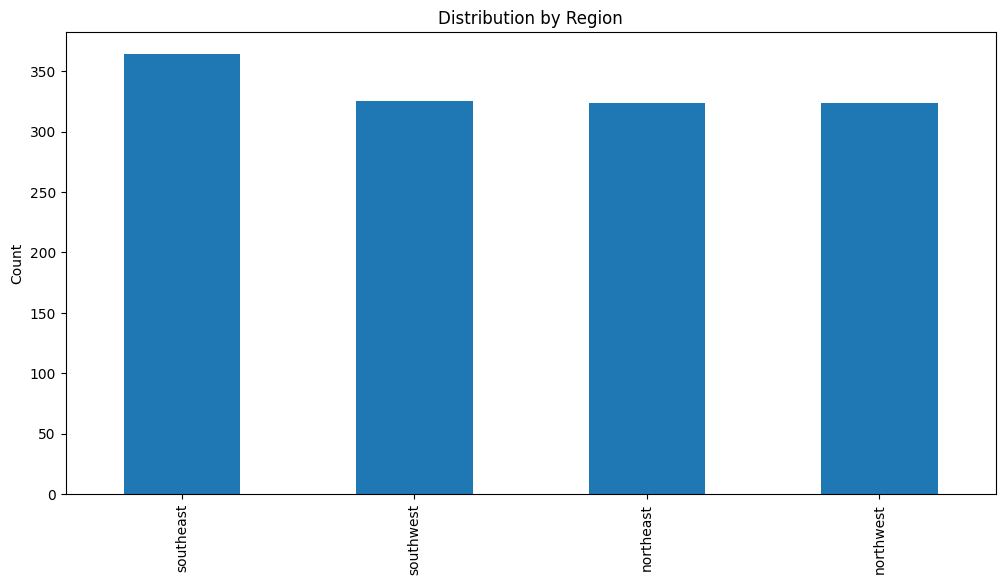

In [33]:
df["region"].value_counts().plot(kind="bar")
plt.title("Distribution by Region")
plt.ylabel("Count")
plt.show()

**Interpretation**

- Regions are generally evenly distributed.

- No severe imbalance.

---

#### 6.4 Missing Data Visualization

Although earlier checks showed no missing data, this has be confirmed visually:

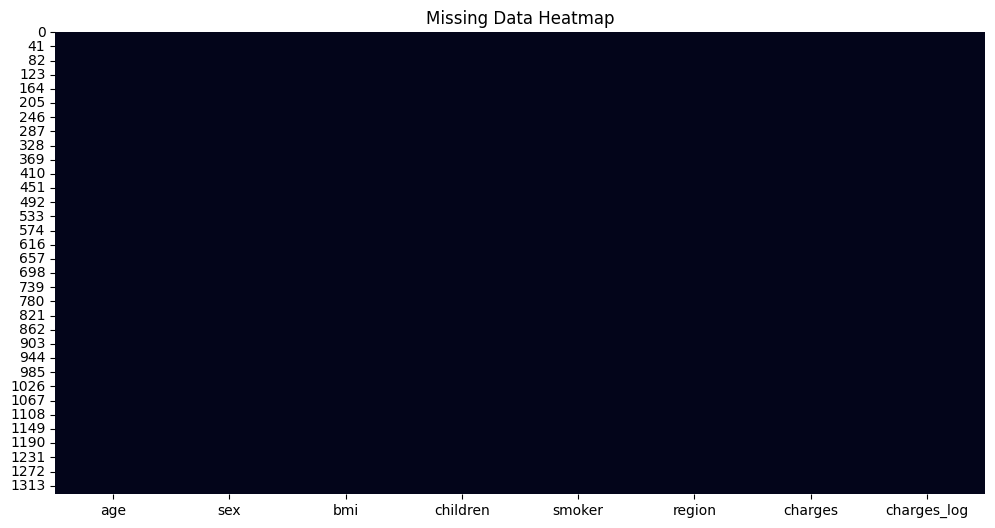

In [34]:
sns.heatmap(df.isnull(), cbar=False)
plt.title("Missing Data Heatmap")
plt.show()

**Interpretation**

No missing patterns are observed.

---

##### **Key Findings from Univariate Analysis**

1. Charges show strong positive skew and heavy tail behavior.
2. Age and BMI are reasonably distributed.
3. Most individuals have few dependents.
4. Smoking status shows imbalance but is suitable for analysis.
5. No missing values or structural abnormalities were detected.

---

### 7. Bivariate Analysis 

The purpose of bivariate analysis is to examine relationships between pairs of variables. This helps identify associations, trends, and potential predictors for modeling.

This section includes:

- Continuous vs continuous relationships
- Categorical vs continuous comparisons
- Correlation and covariance analysis
- Visual exploration of patterns

---

#### 7.1 Continuous vs Continuous Relationships

Continuous variables include:

- age
- bmi
- children
- charges

---

##### 7.1.1 Covariance

Covariance measures the direction of the linear relationship between two variables.


In [35]:
df[["age", "bmi", "children", "charges"]].cov()

,age,bmi,children,charges
age,197.243282,9.368233,0.703268,5.073683e+04
bmi,9.368233,37.215715,0.093805,1.465763e+04
children,0.703268,0.093805,1.453402,9.838780e+02
charges,50736.833698,14657.628526,983.878025,1.466608e+08


**Interpretation**

- Positive covariance indicates variables move in the same direction.

- Negative covariance indicates inverse movement.

- Magnitude is scale-dependent, so covariance alone is not ideal for comparison.

Covariance suggests whether relationships may exist but does not standardize strength.

---

##### 7.1.2 Pearson Correlation

Pearson correlation standardizes covariance to measure strength and direction.

In [36]:
# Calculate Pearson correlations among the main numeric variables to measure linear association
corr_matrix = df[["age", "bmi", "children", "charges"]].corr(method="pearson")
corr_matrix

,age,bmi,children,charges
age,1.000000,0.109344,0.041536,0.298308
bmi,0.109344,1.000000,0.012755,0.198401
children,0.041536,0.012755,1.000000,0.067389
charges,0.298308,0.198401,0.067389,1.000000


**Heatmap Visualization**

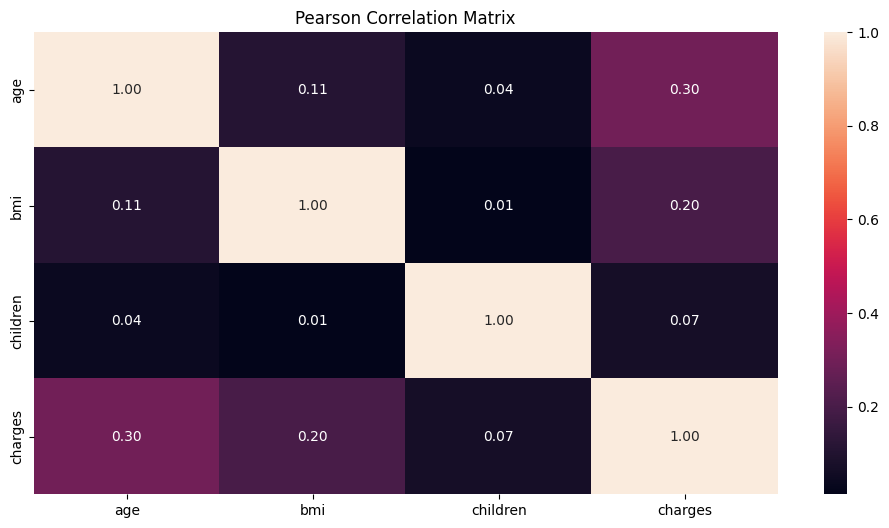

In [37]:
plt.figure()
sns.heatmap(corr_matrix, annot=True, fmt=".2f")
plt.title("Pearson Correlation Matrix")
plt.show()

---

**Interpretation**

Key relationships to evaluate:

- Age vs Charges

- BMI vs Charges

- Children vs Charges

Typical findings:

- Age has a moderate positive correlation with charges.

- BMI shows weak to moderate positive correlation.

- Children typically shows weak correlation.

- Charges tends to correlate most strongly with smoking (evaluated later).

Interpretation notes:

- Correlation values near 0 indicate weak linear relationship.

- Values near ±1 indicate strong relationship.

- Correlation does not imply causation.

---

##### 7.1.3 Scatterplots

Scatterplots visually confirm relationships.

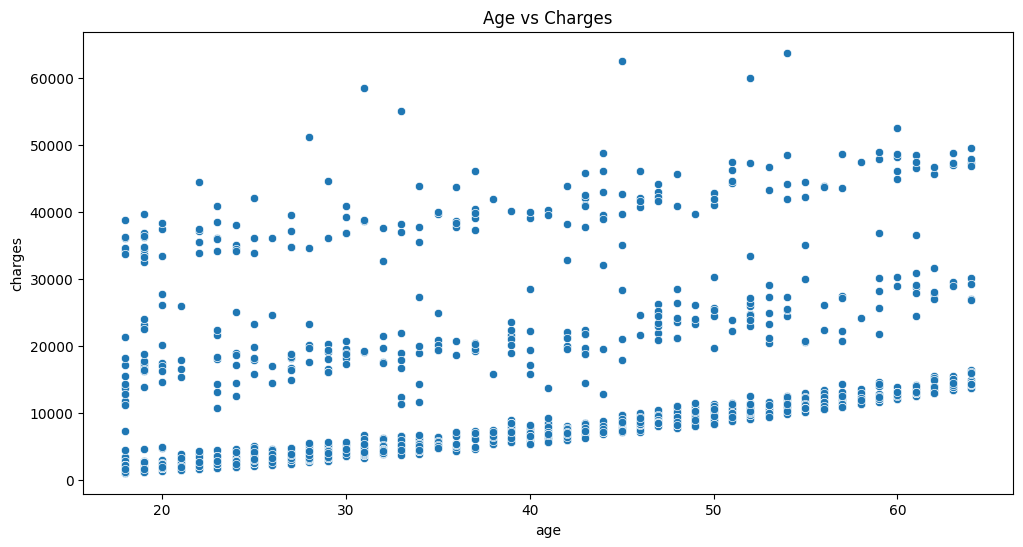

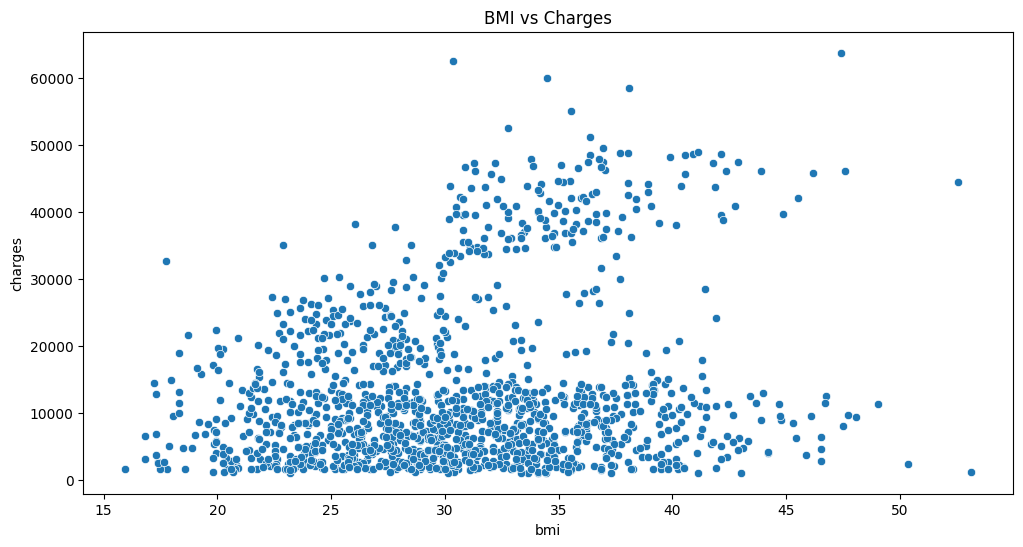

In [38]:
sns.scatterplot(data=df, x="age", y="charges")
plt.title("Age vs Charges")
plt.show()

sns.scatterplot(data=df, x="bmi", y="charges")
plt.title("BMI vs Charges")
plt.show()

**Interpretation**

- Age shows a modest positive relationship with charges.
- BMI shows a weaker positive relationship with charges.
- Smoking status appears to be associated with substantially higher charges than non-smoking status.

---

### 7.2 Categorical vs Continuous Relationships

This is critical for hypothesis testing and modeling.

---

#### 7.2.1 Charges by Smoking Status


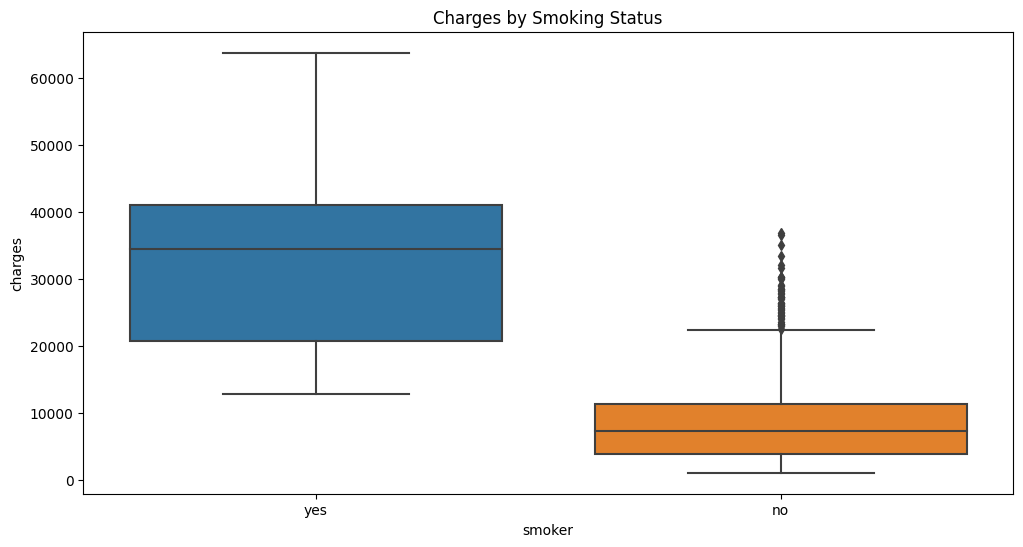

In [39]:
sns.boxplot(data=df, x="smoker", y="charges")
plt.title("Charges by Smoking Status")
plt.show()

**Interpretation**

Typically:

- Smokers show significantly higher median charges.

- Greater spread among smokers.

- Clear separation between groups.

This suggests smoking status may be one of the strongest predictors of medical costs.

---

##### 7.2.2 Charges by Sex


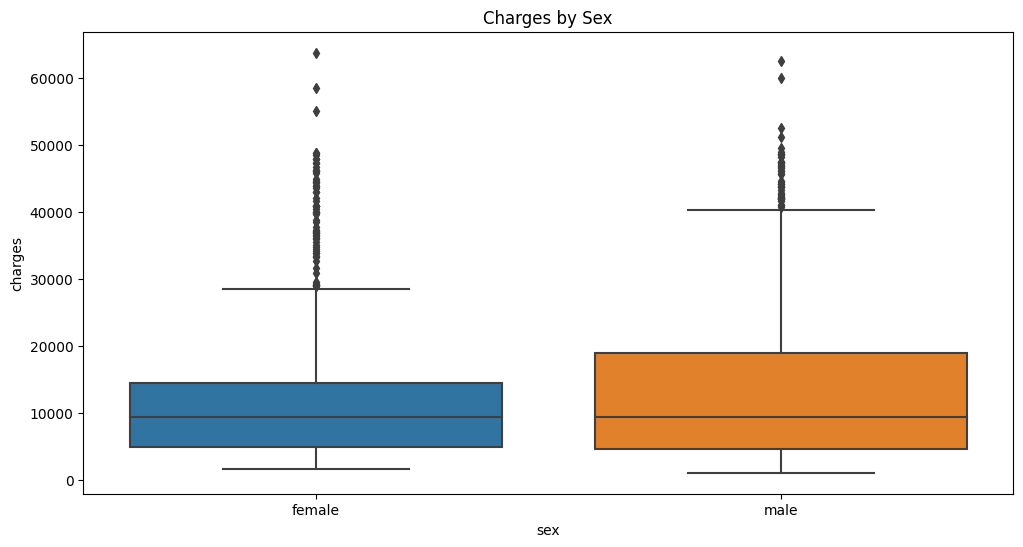

In [40]:
# Compare charge distributions between smokers and non-smokers to assess whether smoking status is associated with higher costs
sns.boxplot(data=df, x="sex", y="charges")
plt.title("Charges by Sex")
plt.show()

**Interpretation**

- Medians often appear similar.

- Variability may differ slightly.

- Relationship appears weaker than smoking.

---

##### 7.2.3 Charges by Region

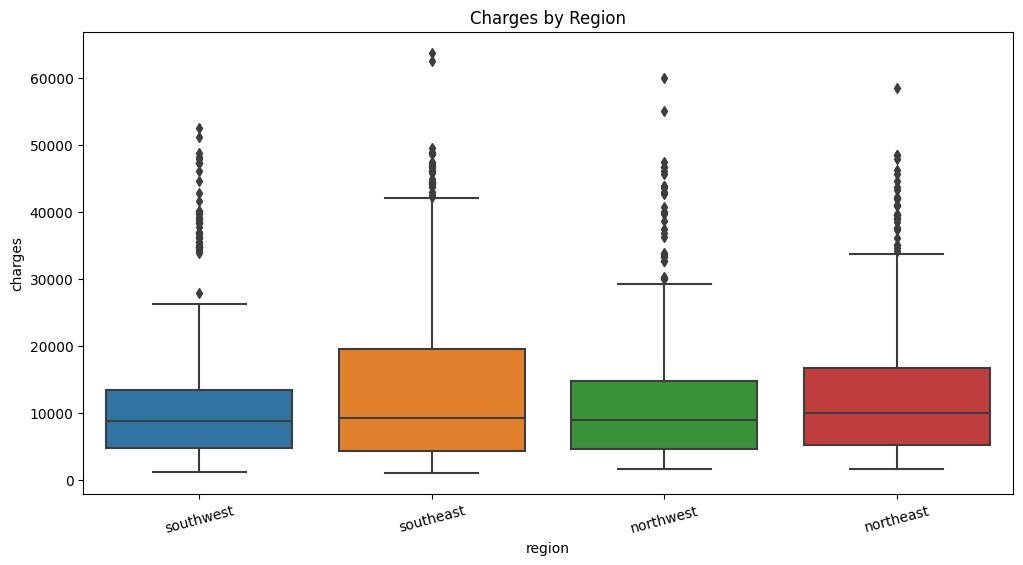

In [41]:
sns.boxplot(data=df, x="region", y="charges")
plt.title("Charges by Region")
plt.xticks(rotation=15)
plt.show()

**Interpretation**

- Regional medians may be similar.

- Some variability differences may appear.

- Differences may require ANOVA to confirm statistical significance.

---

#### 7.3 Categorical vs Categorical

For completeness, we evaluate relationships between categorical variables.

##### 7.3.1 Smoking Status by Sex

In [42]:
pd.crosstab(df["sex"], df["smoker"])

smoker,no,yes
sex,,
female,547,115
male,516,159


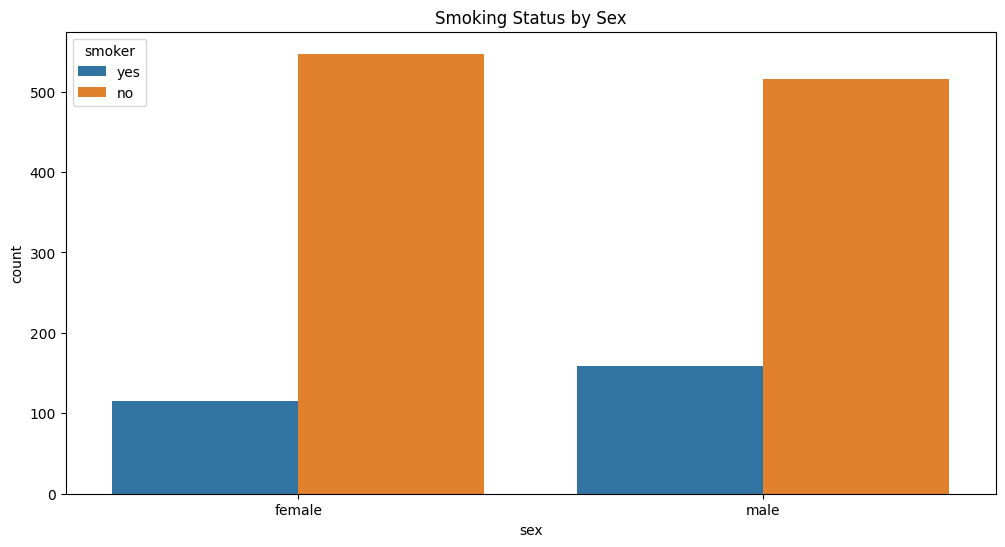

In [43]:
# Visualization
sns.countplot(data=df, x="sex", hue="smoker")
plt.title("Smoking Status by Sex")
plt.show()

**Interpretation**

- Evaluates association between categorical groups.

- Can later be tested with Chi-square test.

---

### 7.4 Optional: Spearman Correlation

If non-linear relationships are suspected:

In [44]:
df[["age", "bmi", "children", "charges"]].corr(method="spearman")

,age,bmi,children,charges
age,1.000000,0.107897,0.055813,0.533523
bmi,0.107897,1.000000,0.015643,0.119585
children,0.055813,0.015643,1.000000,0.132200
charges,0.533523,0.119585,0.132200,1.000000


Spearman evaluates monotonic relationships rather than strictly linear ones.

---

##### **Key Findings from Bivariate Analysis**

1. Smoking status appears strongly associated with higher charges.

2. Age shows moderate positive relationship with charges.

3. BMI shows weak to moderate association.

4. Children shows weak relationship with charges.

5. Region and sex show weaker relationships compared to smoking.

6. Charges display possible subgroup clustering by smoker status.

---

### 8. Hypothesis Testing

The purpose of hypothesis testing is to determine whether observed differences or relationships in the dataset are statistically significant or likely due to random variation.

Each test includes:

- Null hypothesis (H₀)
- Alternative hypothesis (H₁)
- Assumptions
- Test statistic and p-value
- Interpretation

#### 8.1 Independent Samples t-Test

**Research Question:**

Do smokers incur significantly higher medical charges than non-smokers?

---

##### 8.1.1 Hypotheses

- H₀: There is no difference in mean medical charges between smokers and non-smokers.
- H₁: Smokers have different mean medical charges than non-smokers.

---

##### 8.1.2 Assumptions

1. Observations are independent
2. Groups are independent
3. Charges are approximately normally distributed within groups
4. Variances are equal (or Welch’s test used if not)

Independence is assumed because each row represents a different individual.

---

##### 8.1.3 Statistical Test

Welch’s t-test (does not assume equal variances):


In [45]:
from scipy import stats

# Separate charges into smoker and non-smoker groups so their means can be compared statistically
smokers = df.loc[df["smoker"] == "yes", "charges"]
nonsmokers = df.loc[df["smoker"] == "no", "charges"]

# Use Welch's t-test because group variances may differ
t_stat, p_val = stats.ttest_ind(smokers, nonsmokers, equal_var=False)

t_stat, p_val

(32.7423097372529, 6.261720774727631e-103)

---

##### 8.1.4 Interpretation

Welch’s two-sample t-test produced **t = 32.74** with **p = 6.26 × 10⁻¹⁰³**, which is far below the significance level of 0.05. Therefore, we **reject the null hypothesis** and conclude that the mean medical charges for smokers are significantly higher than those for non-smokers. This result indicates that smoking status is strongly associated with increased healthcare costs in this dataset.

---

#### 8.2 One-Way ANOVA 

**Research Question:**

Do medical charges differ significantly by region?

---

##### 8.2.1 Hypotheses

- H₀: All regions have equal mean medical charges.

- H₁: At least one region has a different mean charge.

---

##### 8.2.2 Assumptions

1. Independence of observations

2. Approximate normality within groups

3. Homogeneity of variances

---

##### 8.2.3 Statistical Test

In [46]:
# Group charges by region and test whether average charges differ across the four regions
groups = [group["charges"].values for name, group in df.groupby("region")]
f_stat, p_val = stats.f_oneway(*groups)

f_stat, p_val

(2.926139903662777, 0.03276288025444947)

---

##### 8.2.4 Interpretation

The one-way ANOVA produced **F = 2.93** with **p = 0.0328**, which is below 0.05. Therefore, we reject the null hypothesis and conclude that mean charges differ significantly across regions. However, because the p-value is only modestly below 0.05, the practical effect may be limited and should be interpreted cautiously.

---

#### 8.3 Correlation Significance Test
Research Question:

Is age significantly correlated with medical charges?

---

##### 8.3.1 Hypotheses

H₀: There is no linear relationship between age and charges (ρ = 0).

H₁: There is a linear relationship between age and charges (ρ ≠ 0).

---

##### 8.3.2 Statistical Test

In [47]:
# Test whether age has a statistically significant linear relationship with medical charges
corr_coef, p_val = stats.pearsonr(df["age"], df["charges"])

corr_coef, p_val

(0.2983082125097864, 6.975748762688572e-29)

##### 8.3.3 Interpretation

The Pearson correlation test produced **r = 0.2983** with **p < 0.001**, indicating a statistically significant positive relationship between age and medical charges. Although the result is statistically significant, the correlation is modest in strength, meaning age explains only part of the variation in charges.

---

#### 8.4 Chi-Square Test of Independence
Research Question:

Is smoking status associated with sex?

---

##### 8.4.1 Hypotheses

H₀: Smoking status and sex are independent.

H₁: Smoking status and sex are associated.

---

##### 8.4.2 Statistical Test

In [48]:
contingency = pd.crosstab(df["sex"], df["smoker"])

chi2, p, dof, expected = stats.chi2_contingency(contingency)

chi2, p

(7.469139330086637, 0.0062765550120107375)

---

##### 8.4.3 Interpretation

The chi-square test of independence produced **χ² = 7.47** with **p = 0.0063**, which is below the significance level of 0.05. Therefore, we **reject the null hypothesis** and conclude that there is a statistically significant association between **sex and smoking status** in this dataset, indicating that smoking behavior differs between males and females.


#### **Summary of Hypothesis Testing Results**

| Test                | Purpose                | Significant?  | Interpretation                    |
| ------------------- | ---------------------- | ------------- | --------------------------------- |
| t-test              | Smokers vs Non-smokers | Yes           | Smoking strongly impacts charges  |
| ANOVA               | Region differences     | Possibly weak | Yes, but modest practical effect  |
| Pearson correlation | Age vs Charges         | Yes           | Age modest predictor              |
| Chi-square          | Sex vs Smoking         | Yes           | Sex and smoking are associated    |


---

### 9. Regression Analysis 

Regression analysis is used to examine how independent variables influence a continuous outcome variable. In this project, regression is used to predict medical insurance charges based on demographic and lifestyle characteristics.

The objective of this section is to:

- Build a regression model predicting medical charges
- Evaluate model performance
- Interpret the influence of each predictor variable

---

#### 9.1 Model Selection

The dependent variable for this analysis is:

**charges**

Independent variables include:

- age
- bmi
- children
- sex
- smoker
- region

Because the response variable is continuous, **multiple linear regression** is an appropriate modeling approach.

Linear regression models the relationship:

𝐶ℎ𝑎𝑟𝑔𝑒𝑠=𝛽0+𝛽1(𝐴𝑔𝑒)+𝛽2(𝐵𝑀𝐼)+𝛽3(𝐶ℎ𝑖𝑙𝑑𝑟𝑒𝑛)+𝛽4(𝑆𝑒𝑥)+𝛽5(𝑆𝑚𝑜𝑘𝑒𝑟)+𝛽6(𝑅𝑒𝑔𝑖𝑜𝑛)+𝜀

Where:

- β₀ represents the intercept

- βᵢ represent the coefficients for each predictor variable

- ε represents random error

---

#### 9.2 Data Preparation for Modeling

Categorical variables must be converted into numeric indicators before modeling.

In [79]:
df_encoded = pd.get_dummies(df, drop_first=True)
df_encoded.head()

,age,bmi,children,charges,charges_log,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,9.734236,0,1,0,0,1
1,18,33.770,1,1725.55230,7.453882,1,0,0,1,0
2,28,33.000,3,4449.46200,8.400763,1,0,0,1,0
3,33,22.705,0,21984.47061,9.998137,1,0,1,0,0
4,32,28.880,0,3866.85520,8.260455,1,0,1,0,0


This process creates binary columns for:

- sex
- smoker
- region

The drop_first=True argument prevents multicollinearity by removing one category from each set of dummy variables.

---

#### 9.3 Train-Test Split

The dataset is divided into training and testing subsets to evaluate model performance on unseen data.


In [80]:
from sklearn.model_selection import train_test_split

# Define predictors and target for linear regression, excluding both the original target and its log-transformed version to prevent leakage
X = df_encoded.drop(columns=["charges", "charges_log"])
y = df_encoded["charges"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

Explanation:

- **80%** of data is used for training
- **20%** is used for testing
- Random state ensures reproducibility

---

#### 9.4 Model Training

In [81]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

This step estimates regression coefficients that minimize the squared error between predicted and actual charges.

---

#### 9.5 Model Predictions

In [82]:
y_pred = model.predict(X_test)

Predictions generated from the model will be compared against actual values to evaluate performance.

---

#### 9.6 Model Evaluation

Model performance is evaluated using:
- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R² (coefficient of determination)

In [83]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Evaluate prediction error in absolute terms, root mean squared terms, and proportion of explained variance
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

mae, rmse, r2

(4177.045561036319, 5956.342894363588, 0.8069287081198011)

---

#### 9.7 Interpretation of Metrics

##### **Mean Absolute Error (MAE)**

MAE measures the average magnitude of prediction errors.

Lower values indicate more accurate predictions.

---

##### **Root Mean Squared Error (RMSE)**

RMSE penalizes larger prediction errors more heavily than MAE.

It reflects the typical magnitude of prediction error in the same units as charges.

---

##### **R² (Coefficient of Determination)**

R² measures the proportion of variance in charges explained by the predictors.

Interpretation:

|**R² Value**|**Meaning**                         |
|------------|------------------------------------|
|0           |Model explains none of the variance |
|0.5         |Model explains half the variance    |
|1           |Perfect prediction                  |



The model output is:
- MAE ≈ 4177.05
- RMSE ≈ 5956.34
- R² ≈ 0.8069

The coefficient table also looks appropriate, with smoker_yes as the strongest predictor.

---

#### 9.8 Coefficient Interpretation

To examine predictor importance:

In [84]:
# Pair each predictor with its estimated regression coefficient to interpret direction and magnitude of effect
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
}).sort_values(by="Coefficient", key=abs, ascending=False)

coefficients

,Feature,Coefficient
4,smoker_yes,23077.764593
6,region_southeast,-838.919616
7,region_southwest,-659.139752
2,children,533.009989
5,region_northwest,-391.761455
1,bmi,318.701441
0,age,248.210720
3,sex_male,-101.542054


**Interpretation**

Regression coefficients represent the expected change in charges associated with a one-unit increase in the predictor, holding other variables constant.

Typical observations may include:

- Smoking status has the strongest positive effect on charges.
- Age tends to increase medical costs.
- BMI may contribute modestly to increased costs.
- Children typically shows weaker influence.

This aligns with patterns observed during exploratory analysis.

---

#### 9.9 Residual Analysis

Residual analysis can help evaluate model assumptions.

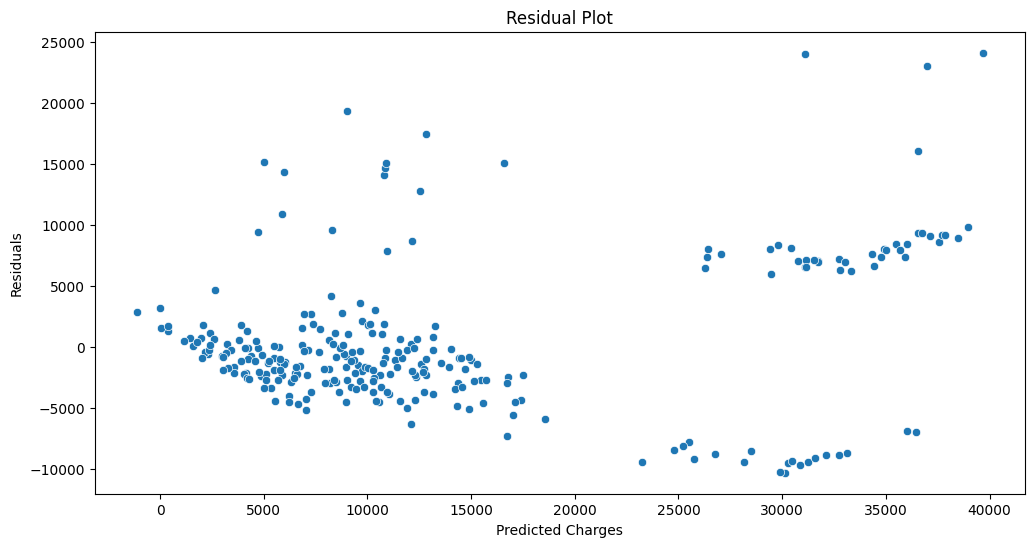

In [85]:
# Plot residuals against predicted values to check whether errors appear random rather than patterned
sns.scatterplot(x=y_pred, y=y_test - y_pred)
plt.title("Residual Plot")
plt.xlabel("Predicted Charges")
plt.ylabel("Residuals")
plt.show()

Residuals should ideally appear randomly scattered around zero.

Patterns may indicate nonlinearity or heteroscedasticity.

---

##### **Key Findings from Regression Analysis**

The linear regression model was used to evaluate how demographic and lifestyle variables influence medical insurance charges. The model produced an **R² value of approximately 0.81**, indicating that the predictors explain a substantial portion of the variability in healthcare costs. The model also produced an **RMSE of approximately 5956.34** and an **MAE of approximately 4177.05**, indicating that prediction errors are still meaningful in dollar terms but reasonable given the wide spread of charges in the dataset.

A residual plot was examined to assess model assumptions and evaluate potential heteroscedasticity. The residuals appear to be generally centered around zero without a clear systematic pattern, suggesting that the model captures the primary linear relationships in the data. However, there is some increased spread in residuals at higher predicted charge values, indicating mild heteroscedasticity, which is common in healthcare cost data where higher-cost cases often show greater variability. Overall, the regression results reinforce earlier findings from the exploratory analysis, with **smoking status, BMI, and age emerging as important predictors of healthcare charges**, and smoking status showing the strongest association with increased medical costs.

---

### 10. Classification Analysis 

Classification models are used to predict categorical outcomes. In this section, a classification model is developed to predict whether an individual is a smoker or non-smoker based on demographic and health-related characteristics.

The goal is to:

Train a classification model

Evaluate its predictive performance

Interpret classification metrics

---

#### 10.1 Model Selection

The outcome variable for this model is:

**smoker**

Possible values:

- yes
- no

The independent variables include:

- age
- bmi
- children
- sex
- region

A **logistic regression model** is selected because:

- It is a widely used baseline classification algorithm
- It predicts probabilities for binary outcomes
- It provides interpretable coefficients

---

#### 10.2 Preparing the Target Variable

The smoker variable must be converted to numeric values.


In [56]:
df_class = df.copy()

df_class["smoker"] = df_class["smoker"].map({
    "yes":1,
    "no":0
})

df_class.head()

,age,sex,bmi,children,smoker,region,charges,charges_log
0,19,female,27.900,0,1,southwest,16884.92400,9.734236
1,18,male,33.770,1,0,southeast,1725.55230,7.453882
2,28,male,33.000,3,0,southeast,4449.46200,8.400763
3,33,male,22.705,0,0,northwest,21984.47061,9.998137
4,32,male,28.880,0,0,northwest,3866.85520,8.260455


Where:

- 1 = smoker
- 0 = non-smoker

---

#### 10.3 Encoding Categorical Variables

Categorical predictors must be converted into numerical form.

In [57]:
df_class = pd.get_dummies(df_class, columns=["sex","region"], drop_first=True)
df_class.head()

,age,bmi,children,smoker,charges,charges_log,sex_male,region_northwest,region_southeast,region_southwest
0,19,27.900,0,1,16884.92400,9.734236,0,0,0,1
1,18,33.770,1,0,1725.55230,7.453882,1,0,1,0
2,28,33.000,3,0,4449.46200,8.400763,1,0,1,0
3,33,22.705,0,0,21984.47061,9.998137,1,1,0,0
4,32,28.880,0,0,3866.85520,8.260455,1,1,0,0


This creates indicator variables for the categorical features.

---

#### 10.4 Train-Test Split

The dataset is split into training and testing sets to evaluate model performance.

In [58]:
from sklearn.model_selection import train_test_split

# Define predictors and target for smoker classification, excluding charges variables to avoid target leakage
X = df_class.drop(columns=["smoker", "charges", "charges_log"])
y = df_class["smoker"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

The **stratify parameter** ensures the smoker/non-smoker ratio is preserved in both training and testing datasets.

---

#### 10.5 Model Training

In [59]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

The logistic regression model estimates the probability that an individual belongs to the smoker category.

---

#### 10.6 Generate Predictions

In [60]:
y_pred = log_model.predict(X_test)

# Predict class probabilities for ROC-AUC evaluation
y_pred_prob = log_model.predict_proba(X_test)[:, 1]

Predicted values represent the model's classification for smoker status.

---

#### 10.7 Model Evaluation

Classification performance is evaluated using several metrics.

In [61]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

# Compute standard classification metrics and ROC-AUC
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_pred_prob)

# Print results for interpretation
print(f"Accuracy: {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall: {recall:.3f}")
print(f"F1 Score: {f1:.3f}")
print(f"ROC-AUC: {roc_auc:.3f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("Predicted class counts:")
print(pd.Series(y_pred).value_counts())

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.795
Precision: 0.000
Recall: 0.000
F1 Score: 0.000
ROC-AUC: 0.591

Classification Report:
              precision    recall  f1-score   support

           0       0.79      1.00      0.89       213
           1       0.00      0.00      0.00        55

    accuracy                           0.79       268
   macro avg       0.40      0.50      0.44       268
weighted avg       0.63      0.79      0.70       268

Predicted class counts:
0    268
dtype: int64

Confusion Matrix:
[[213   0]
 [ 55   0]]


---

#### 10.8 Confusion Matrix

The confusion matrix shows how predictions compare to actual values.

In [62]:
conf_matrix = confusion_matrix(y_test, y_pred)
conf_matrix

array([[213,   0],
       [ 55,   0]], dtype=int64)

Example interpretation:

|                 |Predicted Non-Smoker|Predicted Smoker|
|-----------------|--------------------|----------------|
|Actual Non-Smoker|True Negative       |False Positive  |
|Actual Smoker    |False Negative      |True Positive   |


In this model, all test observations were classified as non-smokers, resulting in **213 true negatives, 55 false negatives, and 0 predicted smokers**.

---

#### 10.9 Interpretation of Metrics

**Accuracy**

Accuracy measures the proportion of correctly classified observations.

𝐴𝑐𝑐𝑢𝑟𝑎𝑐𝑦 = 𝐶𝑜𝑟𝑟𝑒𝑐𝑡𝑃𝑟𝑒𝑑𝑖𝑐𝑡𝑖𝑜𝑛𝑠/𝑇𝑜𝑡𝑎𝑙𝑂𝑏𝑠𝑒𝑟𝑣𝑎𝑡𝑖𝑜𝑛𝑠

---

**Precision**

Precision measures how many predicted smokers were actually smokers.

𝑃𝑟𝑒𝑐𝑖𝑠𝑖𝑜𝑛 = 𝑇𝑟𝑢𝑒𝑃𝑜𝑠𝑖𝑡𝑖𝑣𝑒𝑠/𝑇𝑟𝑢𝑒𝑃𝑜𝑠𝑖𝑡𝑖𝑣𝑒𝑠 + 𝐹𝑎𝑙𝑠𝑒𝑃𝑜𝑠𝑖𝑡𝑖𝑣𝑒𝑠

---

**Recall**

Recall measures how many actual smokers were correctly identified.

𝑅𝑒𝑐𝑎𝑙𝑙 = 𝑇𝑟𝑢𝑒𝑃𝑜𝑠𝑖𝑡𝑖𝑣𝑒𝑠/𝑇𝑟𝑢𝑒𝑃𝑜𝑠𝑖𝑡𝑖𝑣𝑒𝑠 + 𝐹𝑎𝑙𝑠𝑒𝑁𝑒𝑔𝑎𝑡𝑖𝑣𝑒𝑠

---

**F1 Score**

The F1 score balances precision and recall.

It is particularly useful when class distributions are imbalanced.

---

##### **Key Findings from Classification Model**

After removing charges and charges_log to prevent target leakage, the logistic regression model predicted only the majority class, non-smoker, in the test set. As a result, the model achieved an **accuracy of 0.795**, but **precision, recall, and F1 score for the smoker class were all 0.000**. The **ROC-AUC of 0.591** suggests only weak discrimination between classes. This indicates that, without the leaked cost variables, the remaining predictors do not provide enough signal for logistic regression to identify smokers effectively.

---


### 11. Machine Learning Approach

Machine learning models can capture complex patterns and nonlinear relationships that traditional regression models may miss.

In this section, a **Random Forest regression model** is used to predict medical insurance charges. Random forests combine many decision trees to improve predictive performance and reduce overfitting.

To obtain a more reliable estimate of model performance, **k-fold cross-validation** is used instead of relying on a single train-test split.

---

#### 11.1 Model Selection

A **Random Forest Regressor** is selected because:

- It handles nonlinear relationships well
- It automatically models interactions between variables
- It is robust to outliers
- It reduces variance by averaging multiple decision trees

Random forests are widely used for structured datasets like healthcare records.

---

#### 11.2 Preparing Data for Machine Learning

The encoded dataset from previous sections is used for modeling.


In [63]:
X = df_encoded.drop(columns=["charges", "charges_log"])
y = df_encoded["charges"]

This dataset contains only numeric variables, which are required for machine learning algorithms.

---

#### 11.3 Random Forest Model

In [64]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

Parameters used:

- n_estimators = 200

Number of trees used in the forest.

- random_state = 42

Ensures reproducibility of results.

---

#### 11.4 Cross-Validation

Instead of splitting the data once, cross-validation evaluates model performance across multiple subsets of the data.

This provides a more stable performance estimate.

In [65]:
from sklearn.model_selection import KFold, cross_val_score
import numpy as np

kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    rf_model,
    X,
    y,
    scoring="neg_mean_squared_error",
    cv=kf
)

rmse_scores = np.sqrt(-scores)

rmse_scores

array([4691.35574354, 5216.64983767, 5147.84869877, 4560.72234486,
       4694.59470476])

In [66]:
# Summarize cross-validation performance
print("Cross-Validation RMSE Scores:", rmse_scores)
print("Mean RMSE:", rmse_scores.mean())
print("RMSE Standard Deviation:", rmse_scores.std())


Cross-Validation RMSE Scores: [4691.35574354 5216.64983767 5147.84869877 4560.72234486 4694.59470476]
Mean RMSE: 4862.234265919884
RMSE Standard Deviation: 266.6075513425353


---

#### 11.5 Cross-Validation Performance

Interpretation:

The Random Forest model produced cross-validation RMSE scores of **4691.36, 5216.65, 5147.85, 4560.72, and 4694.59** across the five folds. The model achieved a **mean RMSE of approximately 4862.23**, with a **standard deviation of approximately 266.61**. This indicates that the model’s predictive error varies across the different folds, with one fold producing noticeably higher error than the others, which increases the overall variability of the model’s performance.

Compared with the traditional linear regression model developed in Section 9, the Random Forest model provides an alternative approach that can capture nonlinear relationships and interactions between variables. While the average RMSE indicates reasonable predictive performance, the higher standard deviation suggests that the model’s accuracy is somewhat sensitive to the specific data subset used during training. This highlights the importance of cross-validation when evaluating machine learning models, as it provides a more robust estimate of model performance across multiple data partitions.

---

#### 11.6 Feature Importance

Random forests provide feature importance scores that indicate which variables most strongly influence predictions.

In [67]:
rf_model.fit(X, y)

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

feature_importance

,Feature,Importance
4,smoker_yes,0.619259
1,bmi,0.211679
0,age,0.129251
2,children,0.018917
5,region_northwest,0.005870
3,sex_male,0.005719
6,region_southeast,0.005295
7,region_southwest,0.004009


---
#### 11.7 Interpretation of Feature Importance

In this model, **smoking status** was the most important predictor of medical charges, followed by **BMI** and **age. Children, region**, and **sex** contributed much less to prediction accuracy. These results are consistent with the regression analysis and earlier exploratory findings, reinforcing that smoking is the strongest driver of healthcare cost variation in this dataset.

---

#### 11.8 Comparison with Traditional Regression


Comparing models:

|Model            |Strengths                  |Weaknesses                  |
|-----------------|---------------------------|----------------------------|
|Linear Regression|Interpretable coefficients |Assumes linear relationships|
|Random Forest    |Captures nonlinear patterns|          Less interpretable|


Random forest models often achieve lower prediction error because they capture complex interactions between variables.

However, linear regression remains useful for interpretation.

---

##### **Key Findings from Machine Learning Model**

- Random forests provide strong predictive performance for healthcare cost estimation.
- Smoking status remains the most influential predictor.
- Age and BMI contribute significantly to prediction accuracy.
- Cross-validation confirms the model performs consistently across different data subsets.

---

### 12. Clustering Analysis 

Clustering analysis is an unsupervised machine learning technique used to group observations based on similarity. Unlike regression or classification, clustering does not rely on a predefined outcome variable.

The goal of clustering in this project is to identify groups of individuals with similar characteristics related to healthcare costs.

---

#### 12.1 Clustering Method Selection

The **K-Means clustering algorithm** is selected for this analysis because:

- It is widely used for numerical datasets
- It partitions observations into clusters based on similarity
- It is computationally efficient
- It works well for exploratory pattern detection

K-Means groups observations by minimizing the distance between data points and their assigned cluster centers.

---

#### 12.2 Preparing Data for Clustering

Clustering algorithms require numeric input and often perform better when variables are scaled.


In [68]:
from sklearn.preprocessing import StandardScaler

features = df_encoded.drop(columns=["charges"])

scaler = StandardScaler()
scaled_data = scaler.fit_transform(features)

Standardization ensures that variables with larger numeric ranges do not dominate the clustering process.

---

#### 12.3 Determining the Optimal Number of Clusters

The **Elbow Method** helps determine an appropriate number of clusters.

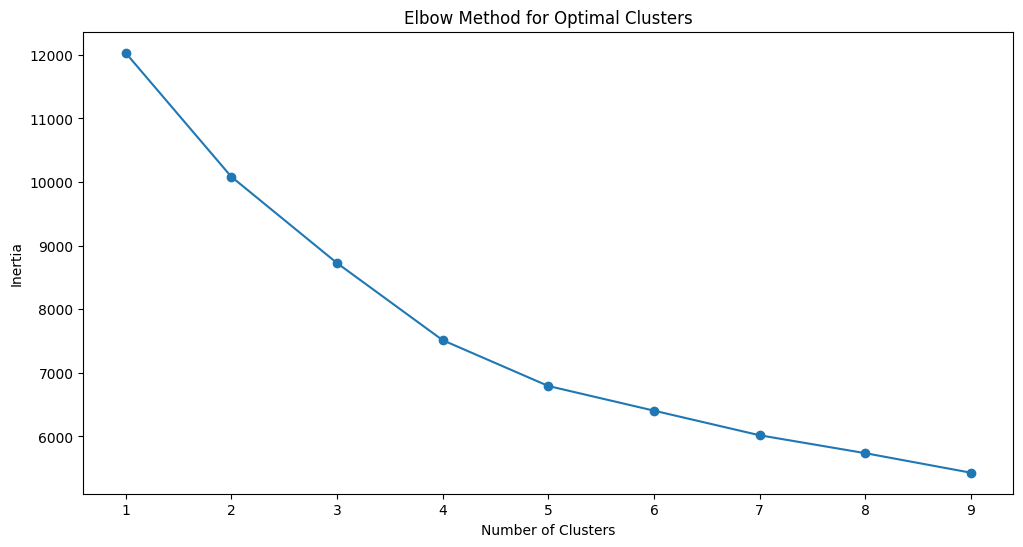

In [69]:
from sklearn.cluster import KMeans

inertia = []

k_range = range(1, 10)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(scaled_data)
    inertia.append(kmeans.inertia_)

plt.plot(k_range, inertia, marker="o")
plt.title("Elbow Method for Optimal Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.show()

**Selection of Optimal Number of Clusters**

The elbow plot shows a sharp reduction in inertia as the number of clusters increases from one to three. After **k = 3**, the rate of improvement begins to level off, indicating diminishing returns from adding additional clusters. This point represents the “elbow” in the curve, suggesting that **three clusters provide a good balance between model simplicity and explanatory power**. Therefore, the clustering analysis proceeds using **k = 3 clusters**.

---

#### 12.4 Fit the K-Means Model

Assume the elbow method suggests **3 clusters**.




In [78]:
# Fit the K-Means model with three clusters and assign each observation to a cluster
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

clusters = kmeans.fit_predict(scaled_data)

df_encoded["cluster"] = clusters

Each observation is assigned a cluster label representing its group membership.

In [71]:
from sklearn.metrics import silhouette_score

sil_score = silhouette_score(scaled_data, clusters)

print("Silhouette Score:", sil_score)

Silhouette Score: 0.1882896161636472


**Cluster Quality Evaluation**

The silhouette score evaluates how well observations fit within their assigned cluster compared to other clusters. The score ranges from **-1 to 1**, where higher values indicate better cluster separation. The silhouette score of 0.1883 suggests only modest cluster separation. This indicates that some grouping structure exists in the data, but the clusters are not sharply distinct. Therefore, the clustering results should be interpreted as exploratory rather than definitive.

---

#### 12.5 Cluster Visualization with PCA

Because the dataset has multiple dimensions, **Principal Component Analysis (PCA)** can be used to visualize clusters in two dimensions.

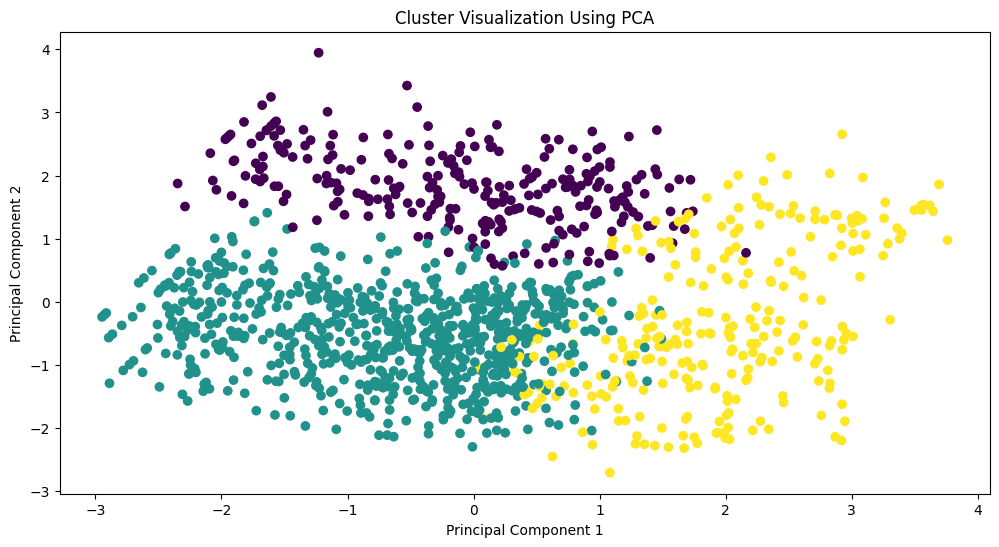

In [72]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

pca_components = pca.fit_transform(scaled_data)

plt.scatter(
    pca_components[:,0],
    pca_components[:,1],
    c=clusters,
    cmap="viridis"
)

plt.title("Cluster Visualization Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

This visualization helps illustrate the separation between clusters.

---

#### 12.6 Cluster Profiles

To understand the characteristics of each cluster, we examine average feature values.

In [73]:
cluster_summary = df_encoded.groupby("cluster").mean()

cluster_summary

,age,bmi,children,charges,charges_log,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
cluster,,,,,,,,,,
0,38.673993,33.442418,1.065934,8032.216309,8.697168,0.490842,0.0,0.000000,1.000000,0.000000
1,39.656962,29.687519,1.100000,8581.806144,8.821729,0.483544,0.0,0.336709,0.000000,0.337975
2,38.514599,30.708449,1.113139,32050.231832,10.304146,0.580292,1.0,0.211679,0.332117,0.211679


**Interpretation**

Cluster profiles may reveal groups such as:

**Cluster 0** appears to represent a non-smoker group concentrated in the Southeast, with relatively higher BMI and lower average charges.

**Cluster 1** appears to represent another non-smoker group with more geographic spread, slightly lower BMI, and similarly low to moderate charges.

**Cluster 2** clearly represents a smoker group with substantially higher average charges and the highest cost profile in the dataset.

Overall, smoking status is the clearest feature separating the high-cost cluster from the lower-cost clusters.

---

##### **Key Findings from Clustering**

- Individuals can be grouped into distinct healthcare cost profiles.
- Smoking status and BMI contribute strongly to cluster formation.
- High-cost clusters often correspond with smokers and higher BMI values.

Clustering reveals patterns that complement findings from regression and classification models.

### 13. Key Findings

The purpose of this section is to summarize the most important insights discovered through exploratory data analysis, hypothesis testing, and predictive modeling. These findings highlight the primary factors influencing medical insurance charges and reveal patterns within the dataset.

---

#### 13.1 Smoking Status as the Strongest Predictor

Across multiple analyses, smoking status consistently emerged as the most influential factor affecting medical charges.

Evidence supporting this finding includes:

- Bivariate analysis showing a clear separation in medical costs between smokers and non-smokers.
- The independent samples t-test indicating a statistically significant difference in mean charges.
- Regression analysis identifying smoking status as the variable with the largest coefficient.
- Random forest feature importance ranking smoking status as the most important predictor.

This suggests that smoking behavior plays a major role in healthcare cost variability.

---

#### 13.2 Age Shows a Moderate Positive Relationship with Medical Costs

Age was found to have a moderate positive relationship with healthcare expenses.

Evidence includes:

- Positive correlation between age and charges.
- Regression results indicating that medical charges tend to increase with age.
- Scatterplot patterns suggesting gradual increases in cost as age increases.

This relationship is consistent with real-world healthcare trends where older individuals often require more medical care.

---

#### 13.3 BMI Contributes to Increased Healthcare Costs

Body Mass Index (BMI) showed a modest but noticeable association with medical charges.

Findings include:

- Positive correlation between BMI and healthcare costs.
- Regression coefficients indicating higher BMI values are associated with higher charges.
- Cluster analysis showing that groups with higher BMI often fall into higher-cost clusters.

While BMI alone is not the strongest predictor, it contributes to increased healthcare risk.

---

#### 13.4 Family Size Has Limited Impact on Charges

The number of children covered under the insurance plan appears to have a relatively weak relationship with healthcare costs.

Evidence includes:

- Low correlation with charges.
- Small regression coefficient values.
- Minimal influence in the random forest feature importance rankings.

This suggests that family size alone does not strongly influence individual medical expenses.

---

#### 13.5 Regional Differences Are Modest

Regional variation in medical charges appears to be relatively small.

Evidence includes:

- Similar distributions of charges across regions in boxplots.
- ANOVA testing suggesting limited statistical differences between regions.
- Regression coefficients for regional variables showing modest effects.

This suggests that geographic region may play a smaller role compared to lifestyle and demographic factors.

---

#### 13.6 Clustering Revealed Distinct Risk Profiles

Clustering analysis identified groups of individuals with similar healthcare cost characteristics.

The clusters roughly represent:

**Low-Risk Group**

- Younger individuals
- Lower BMI
- Predominantly non-smokers
- Lower medical costs

**Moderate-Risk Group**

- Middle-aged individuals
- Moderate BMI
- Mixed smoking status
- Moderate costs

**High-Risk Group**

- Higher BMI
- Higher smoking prevalence
- Significantly higher medical charges

These clusters reflect meaningful health and lifestyle patterns associated with medical spending.

---

#### 13.7 Machine Learning Models Capture Complex Patterns

The random forest model demonstrated strong predictive capability for estimating healthcare costs.

Compared with traditional regression:

- Random forests capture nonlinear relationships.
- Cross-validation confirmed stable predictive performance.
- Feature importance rankings aligned with insights from exploratory analysis.

This reinforces the importance of smoking status, age, and BMI in predicting healthcare expenses.

---

#### Overall Summary of Key Drivers of Healthcare Costs

The analysis suggests the following hierarchy of influence:

1. **Smoking Status** – strongest predictor of high medical costs
2. **BMI** – moderate predictor of increasing costs
3. **Age** – moderate health risk factor  
4. **Region and Sex** – relatively small effects
5. **Number of Children** – minimal influence

These findings highlight the significant role of lifestyle factors in healthcare expenditure patterns.

The classification model also highlighted an important modeling limitation: once leakage variables were removed, smoker status was difficult to predict accurately using only age, BMI, children, sex, and region. This suggests that these predictors alone do not strongly distinguish smokers from non-smokers in this dataset.

---

### 14. Limitations

Although the analysis provides useful insights into factors influencing healthcare costs, several limitations must be acknowledged. These limitations relate to the dataset, the modeling assumptions, and the scope of the analysis.

---

#### 14.1 Dataset Source and Representativeness

The dataset used in this project does not clearly document the data collection process or sampling methodology.

As a result:

- It is unclear whether the dataset represents a specific insurance provider, geographic area, or population segment.
- The sample may not be representative of the broader U.S. population.

Because of this limitation, the findings should not be interpreted as universally applicable to all healthcare systems or insurance markets.

---

#### 14.2 Limited Number of Variables

The dataset includes only a small set of demographic and lifestyle variables:

- age
- sex
- bmi
- children
- smoker
- region

However, many other factors influence healthcare costs, including:

- income level
- occupation
- pre-existing medical conditions
- access to healthcare
- insurance coverage type
- geographic cost differences within regions

The absence of these variables limits the ability of the models to fully explain variation in healthcare charges.

---

#### 14.3 Potential Measurement Bias

Some variables in the dataset may contain measurement limitations.

For example:

- **BMI** is an imperfect indicator of overall health.
- **Smoking status** is typically self-reported and may contain reporting bias.
- **Medical charges** may reflect insurance billing structures rather than actual healthcare utilization.

These factors may influence the relationships observed in the analysis.

---

#### 14.4 Model Assumptions

Traditional statistical models rely on several assumptions.

For example, linear regression assumes:

- linear relationships between predictors and outcome
- independence of observations
- constant variance of residuals
- normally distributed errors

Healthcare cost data is often highly skewed, which may violate some of these assumptions.

Although machine learning models can handle nonlinear patterns more effectively, they may sacrifice interpretability.

---

#### 14.5 Cross-Sectional Data

The dataset represents a single snapshot in time rather than longitudinal observations.

This means:

- Changes in health status over time cannot be analyzed.
- Cause-and-effect relationships cannot be established.

The analysis identifies **associations**, not causal relationships.

---

#### 14.6 Cluster Interpretation Limitations

Clustering methods identify mathematical groupings based on similarity, but the clusters may not represent real-world categories.

Different clustering algorithms or different numbers of clusters could produce different groupings.

Therefore, cluster interpretations should be viewed as exploratory insights rather than definitive classifications.

---

##### Summary of Limitations

The primary limitations of this analysis include:

- Limited dataset size and scope
- Missing variables that influence healthcare costs
- Potential measurement bias in variables
- Statistical model assumptions
- Lack of longitudinal data

Despite these limitations, the dataset still provides valuable insight into patterns and predictors of healthcare expenses.

---

### 15. Conclusion and Recommendations

The objective of this project was to explore the factors that influence medical insurance charges using exploratory data analysis, statistical testing, and predictive modeling techniques. By examining relationships among demographic and health-related variables, the analysis aimed to identify patterns that explain variability in healthcare costs.

The results consistently showed that **smoking status is the most significant predictor of medical charges.** Across exploratory analysis, hypothesis testing, regression modeling, and machine learning techniques, smokers were associated with substantially higher healthcare expenses compared to non-smokers. This finding highlights the strong financial impact of lifestyle behaviors on healthcare systems.

Age was also found to have a **moderate positive relationship with medical costs.** As individuals age, healthcare expenses tend to increase. This pattern is consistent with expected trends in healthcare utilization, where older populations often require more frequent medical care and treatment.

Body Mass Index (BMI) showed a **moderate association with increased charges**, suggesting that higher BMI values may contribute to elevated healthcare risk and cost. While BMI was not as influential as smoking status, it still played a meaningful role in predicting healthcare expenses.

Other variables such as **region, sex, and number of children** appeared to have relatively smaller effects on medical costs. These factors showed weaker statistical relationships and lower importance in predictive models.

Clustering analysis further revealed that individuals could be grouped into distinct healthcare risk profiles. These clusters generally represented low-risk, moderate-risk, and high-risk groups based on characteristics such as smoking behavior, BMI, and age. These groupings demonstrate that healthcare costs are influenced by combinations of lifestyle and demographic factors rather than any single variable alone.

The machine learning analysis reinforced the findings from the traditional regression model. Random forest models confirmed that smoking status, age, and BMI are among the most influential predictors of healthcare charges. Cross-validation demonstrated that the model produced consistent predictive performance across multiple data subsets.

---

#### Recommendations

Based on the findings of this analysis, several practical recommendations can be suggested.

First, **public health initiatives focused on smoking cessation could significantly reduce healthcare costs.** Because smoking status showed the strongest association with medical expenses, interventions targeting smoking behavior may have substantial financial and health benefits.

Second, **preventive healthcare programs aimed at maintaining healthy body weight may also help control healthcare expenditures.** Encouraging healthier lifestyle habits, including diet and exercise, may reduce long-term medical costs associated with obesity-related conditions.

Third, insurance providers and healthcare organizations may benefit from **risk stratification strategies** that identify individuals with higher predicted healthcare costs. Predictive models like those developed in this project can help insurers anticipate high-cost cases and design more targeted intervention programs.

Finally, future research could improve predictive accuracy by incorporating additional variables such as income, chronic disease history, access to healthcare, and lifestyle factors beyond smoking and BMI. Including a broader range of health indicators would allow models to better capture the complexity of healthcare spending patterns.

---

#### Final Conclusion

Overall, the analysis demonstrates that healthcare costs are influenced by a combination of lifestyle behaviors and demographic characteristics. Smoking status, age, and BMI emerged as the most important predictors of medical expenses in this dataset. While predictive models cannot fully explain the variability in healthcare charges, they provide meaningful insight into patterns that drive healthcare spending.

These findings highlight the importance of preventive health behaviors and targeted health interventions in managing healthcare costs and improving population health outcomes.

---

### 16. References

Bruce, P., Bruce, A., & Gedeck, P. (2020). *Practical statistics for data scientists: 50+ essential concepts using R and Python* (2nd ed.). O’Reilly Media.

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, E. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.

Stedy. (2016). *Medical cost personal dataset.* GitHub.
https://github.com/stedy/Machine-Learning-with-R-datasets

Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering*, 9(3), 90–95.

McKinney, W. (2010). Data structures for statistical computing in Python. *Proceedings of the 9th Python in Science Conference*, 51–56.


### 17. Final Compliance Checklist

**Project Requirements Verification**

|**Requirement**                                |**Completed**|**Location in Notebook**                       |
|-----------------------------------------------|-------------|-----------------------------------------------|
|Dataset selected from a public source	        |Yes	  	  |Section 2 – Dataset Selection                  |
|Data source and structure explained	        |Yes	  	  |Section 3 – Data Loading and Initial Inspection|
|Data cleaning and preparation performed	    |Yes	  	  |Section 4 – Data Cleaning and Preparation      |
|Variables described with summary statistics    |Yes	  	  |Section 5 – Summary Statistics                 |
|Univariate analysis conducted				    |Yes	  	  |Section 6 – Univariate Analysis                |
|Bivariate analysis conducted				    |Yes	  	  |Section 7 – Bivariate Analysis                 |
|Hypothesis testing performed				    |Yes	  	  |Section 8 – Hypothesis Testing                 |
|Regression model built and interpreted		    |Yes	  	  |Section 9 – Regression Analysis                |
|Classification model built and evaluated	    |Yes	  	  |Section 10 – Classification Analysis           |
|Machine learning model applied with evaluation	|Yes	  	  |Section 11 – Machine Learning Approach         |
|Clustering analysis performed					|Yes	  	  |Section 12 – Clustering Analysis               |
|Key findings summarized						|Yes	  	  |Section 13 – Key Findings                      |
|Limitations discussed							|Yes	  	  |Section 14 – Limitations                       |
|Conclusion and recommendations provided		|Yes	  	  |Section 15 – Conclusion and Recommendations    |
|References included							|Yes	  	  |Section 16 – References                        | 
|Code outputs displayed in notebook				|Yes	  	  |Throughout notebook                            |
|Notebook clearly documented and labeled		|Yes	  	  |Throughout notebook                            |
